# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

##Introduction
This notebook explores Amazon product reviews through three data science tasks: natural language processing, time-series analysis, and neural-network classification. It examines review language, analyzes review activity over time, and builds a model to predict star ratings from review text. The dataset contains 997 reviews, so findings and model performance should be interpreted with that limited sample in mind.

## 0. Setup



In [27]:
import copy, html, random, re, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

SEED = 42                       # reused for every random operation in the notebook
random.seed(SEED)
np.random.seed(SEED)

# consistent, high-contrast visual style
PALETTE = {"teal": "#1B998B", "coral": "#E4572E", "navy": "#26547C",
           "gold": "#F2A900", "purple": "#7B2CBF", "grey": "#6C757D"}
RATING_COLORS = {1: "#C1121F", 2: "#F77F00", 3: "#F2A900", 4: "#6A994E", 5: "#1B998B"}
plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
    "axes.spines.right": False, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "legend.frameon": False,
})


# Part 1: NLP

**Goal.** Turn raw review text into clean tokens, then explore which words and phrases customers use – overall and in low- vs high-rated reviews.

## 1.1 Load and inspect the data


In [28]:
df = pd.read_csv('amazon_reviews_lab.csv')

print("Shape (rows, columns):", df.shape)
print("\nColumns and types:")
print(df.dtypes.to_string())

# handling of missing / malformed values
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
print("\nMissing values per column:")
print(df.isna().sum().to_string())
df = df.dropna(subset=["rating"]).copy()          # a review without a rating cannot be used
df["rating"] = df["rating"].astype(int)
df["review_text"] = df["review_text"].fillna("").astype(str)
print("Empty review texts:", (df["review_text"].str.strip() == "").sum())
print("Exact duplicate review texts:", df["review_text"].duplicated().sum())
print("Distinct products:", df["product_id"].nunique())

print("\nRating distribution:")
rating_counts = df["rating"].value_counts().sort_index()
print(pd.DataFrame({"count": rating_counts, "share_%": (rating_counts / len(df) * 100).round(1)}).to_string())

print("\nrating vs sentiment_label (is the label derived from the rating?)")
print(pd.crosstab(df["rating"], df["sentiment_label"]).to_string())

same_len = (df["review_length_words"] == df["review_text"].str.split().str.len()).mean()
print(f"\nreview_length_words equals a whitespace word count in {same_len:.0%} of rows")

print("\nThree random reviews (first 250 characters):")
for _, row in df.sample(3, random_state=SEED).iterrows():
    print(f"  [{row['rating']} stars] {row['review_text'][:250]!r}")

Shape (rows, columns): (997, 9)

Columns and types:
product_id              object
rating                   int64
review_text             object
review_summary          object
review_time_raw         object
unix_review_time       float64
timestamp               object
sentiment_label         object
review_length_words      int64

Missing values per column:
product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
Empty review texts: 0
Exact duplicate review texts: 0
Distinct products: 40

Rating distribution:
        count  share_%
rating                
1          87      8.7
2          48      4.8
3          94      9.4
4         188     18.9
5         580     58.2

rating vs sentiment_label (is the label derived from the rating?)
sentiment_label  negative  neutral  positive
rating                                      




- There are **997 reviews**, no missing values and no duplicate review texts, so no rows need to be dropped.
- The ratings are **strongly skewed**: 5-star reviews are about 58% of the data and 1–2 star reviews only about 14% (135 reviews). This matters for every later step – word counts are dominated by happy customers, and the classifier in Part 3 will find the minority ratings harder.
- sentiment_label maps exactly onto rating (1–2 negative, 3 neutral, 4–5 positive), so it carries no independent information and is excluded from modelling.
- The reviews are very uneven in length (see the next chart), so a few long reviews can dominate raw word counts. We therefore report **document frequency** (how many reviews contain a word) alongside raw counts.

The next cell visualises the rating distribution and review length.

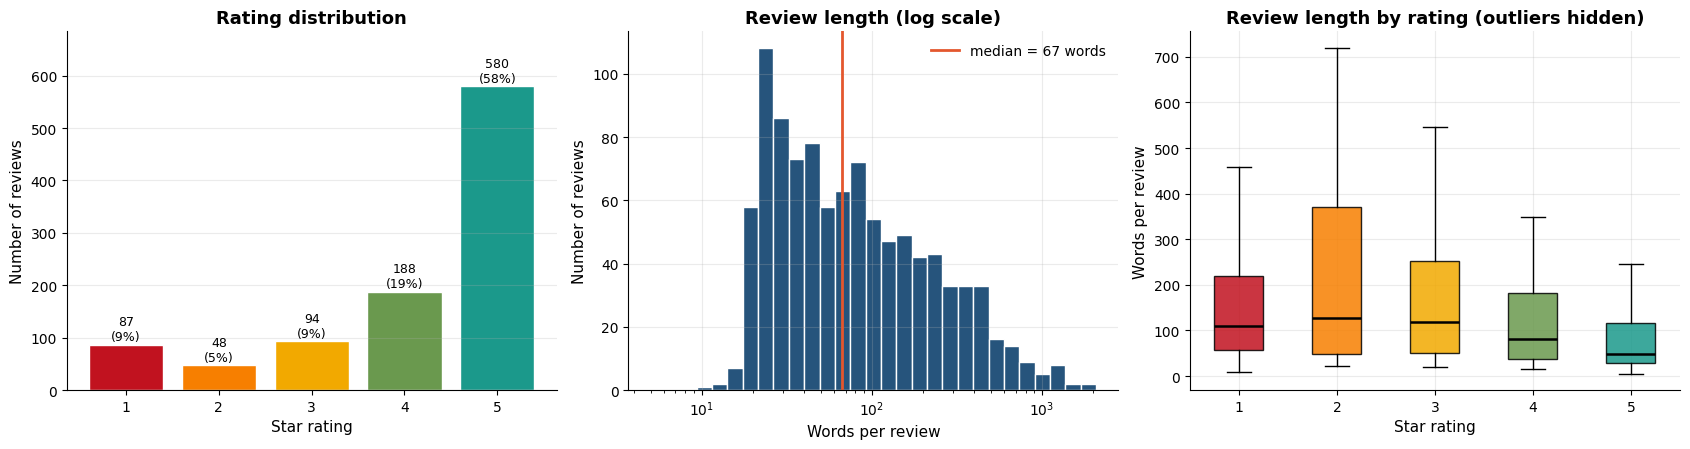

Median words per review by rating: {1: 110.0, 2: 126.5, 3: 117.5, 4: 81.0, 5: 49.0}
Longest review: 2079 words; shortest: 5 words


In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# (1) rating distribution
ax = axes[0]
bars = ax.bar(rating_counts.index, rating_counts.values,
              color=[RATING_COLORS[r] for r in rating_counts.index], edgecolor="white")
for b, v in zip(bars, rating_counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 8, f"{v}\n({v / len(df):.0%})", ha="center", fontsize=9)
ax.set_title("Rating distribution"); ax.set_xlabel("Star rating"); ax.set_ylabel("Number of reviews")
ax.set_ylim(0, rating_counts.max() * 1.18); ax.grid(axis="x", visible=False)

# (2) review length (log-scaled because the distribution is very right-skewed)
ax = axes[1]
lengths = df["review_length_words"].clip(lower=1)
ax.hist(lengths, bins=np.logspace(np.log10(lengths.min()), np.log10(lengths.max()), 30),
        color=PALETTE["navy"], edgecolor="white")
ax.axvline(lengths.median(), color=PALETTE["coral"], lw=2, label=f"median = {lengths.median():.0f} words")
ax.set_xscale("log"); ax.legend()
ax.set_title("Review length (log scale)"); ax.set_xlabel("Words per review"); ax.set_ylabel("Number of reviews")

# (3) length by rating
ax = axes[2]
groups = [df.loc[df["rating"] == r, "review_length_words"] for r in range(1, 6)]
bp = ax.boxplot(groups, patch_artist=True, medianprops=dict(color="black", lw=1.8), showfliers=False)
for patch, r in zip(bp["boxes"], range(1, 6)):
    patch.set_facecolor(RATING_COLORS[r]); patch.set_alpha(0.85)
ax.set_xticks(range(1, 6)); ax.set_xticklabels(range(1, 6))
ax.set_title("Review length by rating (outliers hidden)"); ax.set_xlabel("Star rating"); ax.set_ylabel("Words per review")

plt.tight_layout(); plt.show()

med = df.groupby("rating")["review_length_words"].median()
print("Median words per review by rating:", med.to_dict())
print(f"Longest review: {df['review_length_words'].max()} words; shortest: {df['review_length_words'].min()} words")

**Reading the charts.**

- **Rating:** 5-star reviews are 58% of the data (580 of 997); 4-star 19%; 3-star 9%; 1-star 9%; 2-star 5%. The data are strongly skewed toward satisfied customers.
- **Length:** the median review is short, but a long right tail exists (the longest is 2,079 words, the shortest 5), which is why the histogram needs a log axis.
- **Length by rating:** unhappy customers write more. Median length is 110 words for 1-star, 126.5 for 2-star and 117.5 for 3-star reviews, against 81 for 4-star and just 49 for 5-star reviews. Longer text is therefore itself a weak signal of a lower rating, and it also means low-rated reviews contribute proportionally more words than their share of the data suggests.

## 1.2 Text preprocessing

In this section, review text is cleaned and prepared for analysis. The preprocessing steps remove URLs and punctuation, convert text to lowercase, tokenize words, remove common stopwords, and lemmatize words so their base forms can be compared more easily.



In [30]:
# Choose tools: NLTK if fully available, otherwise a documented fallback
USE_NLTK = False
try:
    import nltk
    from nltk.corpus import stopwords
    from nltk.stem import WordNetLemmatizer

    def _ensure_nltk(resource_path, package):
        try:
            nltk.data.find(resource_path)
            return True
        except LookupError:
            print(f"NLTK resource '{package}' not found - attempting a one-off download ...")
            try:
                return bool(nltk.download(package, quiet=True))
            except Exception:
                return False

    if _ensure_nltk("corpora/stopwords", "stopwords") and _ensure_nltk("corpora/wordnet", "wordnet"):
        _base_stop = set(stopwords.words("english"))
        _lemmatizer = WordNetLemmatizer()
        _lemmatizer.lemmatize("tests")          # raises LookupError if WordNet is unusable
        USE_NLTK = True
except Exception as exc:                         # ImportError, LookupError, network problems ...
    print(f"NLTK unavailable ({type(exc).__name__}); using the scikit-learn fallback.")

if not USE_NLTK:
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
    _base_stop = set(ENGLISH_STOP_WORDS)

    def _fallback_lemma(w):
        # Very small rule-based lemmatiser (plural endings only).
        if len(w) > 4 and w.endswith("ies"):
            return w[:-3] + "y"
        if len(w) > 4 and w.endswith(("sses", "xes", "ches", "shes")):
            return w[:-2]
        if len(w) > 3 and w.endswith("s") and not w.endswith(("ss", "us", "is")):
            return w[:-1]
        return w

KEEP_WORDS = {"no", "nor", "not", "never", "none", "nothing", "cannot", "without", "neither"}
STOP_WORDS = _base_stop - KEEP_WORDS
print("Backend:", "NLTK (stopwords + WordNet lemmatiser)" if USE_NLTK else "scikit-learn stop-words + rule-based lemmatiser (fallback)")
print("Stop-words in use:", len(STOP_WORDS), "| negations kept:", sorted(KEEP_WORDS & _base_stop))

def lemmatize_token(tok):
    if USE_NLTK:
        return _lemmatizer.lemmatize(_lemmatizer.lemmatize(tok), pos="v")   # noun pass, then verb pass
    return _fallback_lemma(tok)

CONTRACTIONS = [(r"\bwon't\b", "will not"), (r"\bcan't\b", "can not"), (r"\bcannot\b", "can not"),
                (r"n't\b", " not"), (r"'re\b", " are"), (r"'ve\b", " have"), (r"'ll\b", " will"),
                (r"'m\b", " am"), (r"'d\b", " would"), (r"'s\b", "")]
# Reviewers often drop the apostrophe ("dont", "didnt"); treat these as negations too.
NEGATION_TYPOS = {"dont", "doesnt", "didnt", "isnt", "wasnt", "arent", "werent", "wont", "cant",
                  "couldnt", "wouldnt", "shouldnt", "hasnt", "havent", "hadnt"}

def preprocess_text(text):
    # Return a list of cleaned, lemmatised tokens for one review.
    if not isinstance(text, str) or not text.strip():
        return []
    t = html.unescape(text)                              # &quot; -> "
    t = re.sub(r"<[^>]+>", " ", t)                       # HTML tags
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)         # URLs
    t = t.replace("\u2019", "'").lower()                 # curly apostrophe, lowercase
    for pattern, repl in CONTRACTIONS:
        t = re.sub(pattern, repl, t)
    t = re.sub(r"[^a-z\s]", " ", t)                      # drop punctuation AND digits
    tokens = [w for w in t.split() if len(w) > 1 and len(w) <= 25]
    tokens = ["not" if w in NEGATION_TYPOS else w for w in tokens]
    tokens = [w for w in tokens if w not in STOP_WORDS]
    return [lemmatize_token(w) for w in tokens]

# quick self-test on a tricky string
print(preprocess_text("I DON'T like it!! Visit http://x.com <b>now</b> &quot;3 stars&quot; - batteries died, won't charge."))
print(preprocess_text(None), preprocess_text(""))

NLTK resource 'wordnet' not found - attempting a one-off download ...
Backend: NLTK (stopwords + WordNet lemmatiser)
Stop-words in use: 195 | negations kept: ['no', 'nor', 'not']
['not', 'like', 'visit', 'star', 'battery', 'die', 'not', 'charge']
[] []


### Quality check: before vs after

Cleaning code can silently go wrong, so we inspect real reviews before and after processing, then check three aggregate properties: how much text survives, that no review becomes empty, and that negations and HTML entities are handled.

In [31]:
df["tokens"] = df["review_text"].apply(preprocess_text)
df["clean_text"] = df["tokens"].str.join(" ")

#before / after on real reviews
short = df[df["review_text"].str.len() < 350]
examples = list(short.sample(3, random_state=SEED).index)
entity_rows = df[df["review_text"].str.contains("&quot;", regex=False)]
if len(entity_rows):
    examples.append(entity_rows.index[0])          # make sure an HTML-entity case is shown

for i in examples:
    print(f"--- review {i} (rating {df.at[i, 'rating']}) ---")
    print("BEFORE:", df.at[i, "review_text"][:350].replace("\n", " "))
    print("AFTER :", " ".join(df.at[i, "tokens"][:45]), "..." if len(df.at[i, "tokens"]) > 45 else "")
    print()

# aggregate checks
raw_words = df["review_text"].str.split().str.len().sum()
kept_tokens = df["tokens"].str.len().sum()
print(f"Words before: {raw_words:,}  |  tokens after: {kept_tokens:,}  |  retained: {kept_tokens / raw_words:.0%}")
print("Reviews left with zero tokens:", int((df["tokens"].str.len() == 0).sum()))
# ('amp' is deliberately not checked: it is also a real word, e.g. "a 2 amp charger")
print("Leftover HTML-entity tokens (quot/nbsp/lt/gt):",
      sum(t in {"quot", "nbsp", "lt", "gt"} for toks in df["tokens"] for t in toks))
neg_share = df["tokens"].apply(lambda toks: "not" in toks).mean()
print(f"Reviews that still contain the negation 'not' after cleaning: {neg_share:.0%}")

--- review 789 (rating 5) ---
BEFORE: Great Mount, so many areas of articulation. This was a great gift idea my mother loves it. I have purchased two of them and they are sturdy and give a touch of class to every room you put them in. A must have any video file or those who want to save space in a bedroom or office.
AFTER : great mount many area articulation great gift idea mother love purchase two sturdy give touch class every room put must video file want save space bedroom office 

--- review 277 (rating 5) ---
BEFORE: Charges quickly. very good set for the price. will review more when field tested. using it for my tactical flashlight used for LE work.
AFTER : charge quickly good set price review field test use tactical flashlight use le work 

--- review 806 (rating 5) ---
BEFORE: Got this for my sons 15th birthday he loves it a great gift for anyone great price and it came fast love amazon
AFTER : get son th birthday love great gift anyone great price come fast love amazon 

--- r



The preprocessing checks are mostly successful: it retains negations, removes HTML fragments, and lemmatizes words, with no reviews left empty. However, removing digits can leave stray text, and some common words remain because they are not in the stopword list. The cleaned output is useful for analysis, but not perfect.

## 1.3 Word frequencies

We count (a) total occurrences and (b) **document frequency** – the percentage of reviews containing the word. Both are shown because a handful of very long reviews, or a few heavily reviewed products, can inflate raw counts.

Total tokens: 74,101 | vocabulary size: 5,543


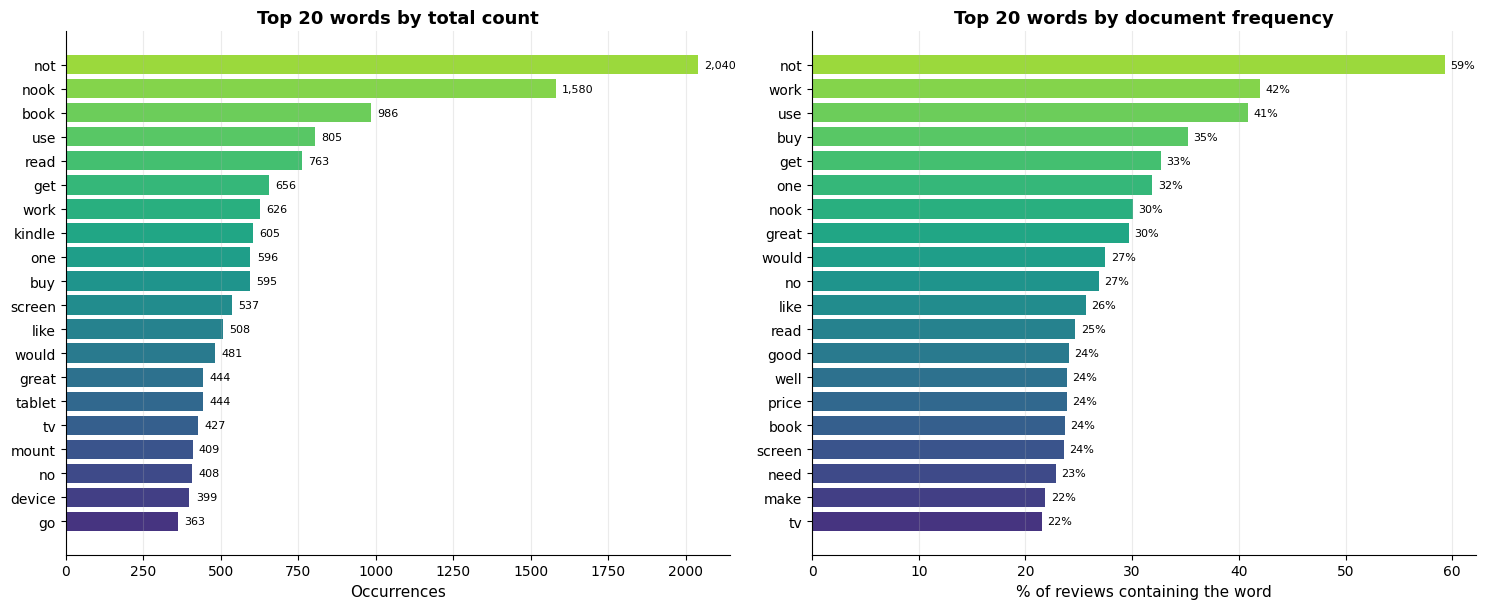

In [32]:
all_tokens = [t for toks in df["tokens"] for t in toks]
word_counts = Counter(all_tokens)
doc_freq = Counter(t for toks in df["tokens"] for t in set(toks))
print(f"Total tokens: {len(all_tokens):,} | vocabulary size: {len(word_counts):,}")

TOP_N = 20
top_words = word_counts.most_common(TOP_N)
top_docs = doc_freq.most_common(TOP_N)

fig, axes = plt.subplots(1, 2, figsize=(15, 6.2))
colors = plt.cm.viridis(np.linspace(0.85, 0.15, TOP_N))      # darkest = most frequent

words, counts = zip(*top_words)
axes[0].barh(words[::-1], counts[::-1], color=colors[::-1])
axes[0].set_title(f"Top {TOP_N} words by total count"); axes[0].set_xlabel("Occurrences")
for y_pos, v in enumerate(counts[::-1]):
    axes[0].text(v + max(counts) * 0.01, y_pos, f"{v:,}", va="center", fontsize=8)

words2, dcounts = zip(*top_docs)
axes[1].barh(words2[::-1], [100 * c / len(df) for c in dcounts[::-1]], color=colors[::-1])
axes[1].set_title(f"Top {TOP_N} words by document frequency"); axes[1].set_xlabel("% of reviews containing the word")
for y_pos, v in enumerate(dcounts[::-1]):
    axes[1].text(100 * v / len(df) + 0.5, y_pos, f"{100 * v / len(df):.0f}%", va="center", fontsize=8)

for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

The cleaned reviews contain 74,101 tokens across 5,543 distinct words. Product names such as “nook,” “kindle,” and “tablet” are frequent, while words like “work,” “use,” and “buy” appear across many reviews. Negations are common, so frequency alone cannot reveal sentiment; context matters.

## 1.4 Which words separate unhappy from happy reviews?

Overall frequency mostly shows words common to *all* reviews ("work", "use", "great"). To see what is **characteristic** of each side, we compare 1–2 star reviews (negative group) with 4–5 star reviews (positive group) using a smoothed **log-odds ratio** (positive value = relatively more frequent in negative reviews). Only words occurring at least 15 times overall are considered, to avoid noisy rare words. The negative group is small (135 reviews), so treat the ranking as indicative, not definitive.

Negative group (1-2 stars): 135 reviews, 14,540 tokens | Positive group (4-5 stars): 768 reviews, 50,068 tokens


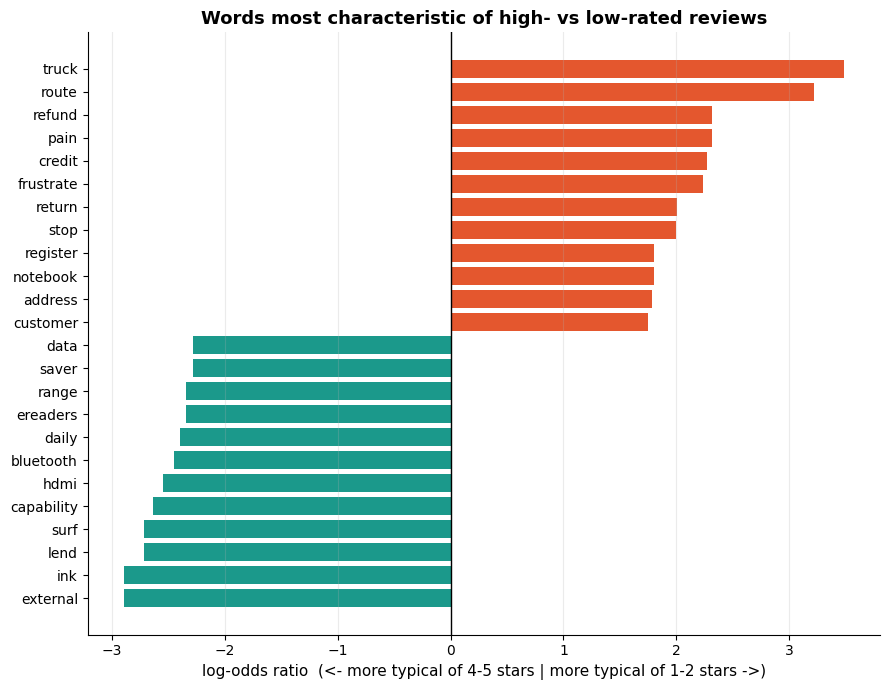

Most characteristic of 1-2 star reviews: truck, route, refund, pain, credit, frustrate, return, stop, register, notebook, address, customer
Most characteristic of 4-5 star reviews: external, ink, lend, surf, capability, hdmi, bluetooth, daily, ereaders, range, saver, data


In [33]:
neg_mask, pos_mask = df["rating"] <= 2, df["rating"] >= 4
neg_counts = Counter(t for toks in df.loc[neg_mask, "tokens"] for t in toks)
pos_counts = Counter(t for toks in df.loc[pos_mask, "tokens"] for t in toks)
n_neg, n_pos = sum(neg_counts.values()), sum(pos_counts.values())
print(f"Negative group (1-2 stars): {int(neg_mask.sum())} reviews, {n_neg:,} tokens | "
      f"Positive group (4-5 stars): {int(pos_mask.sum())} reviews, {n_pos:,} tokens")

vocab = [w for w in word_counts if word_counts[w] >= 15]
alpha = 0.5                                                   # additive smoothing
log_odds = pd.Series({
    w: np.log((neg_counts[w] + alpha) / (n_neg + alpha * len(vocab)))
       - np.log((pos_counts[w] + alpha) / (n_pos + alpha * len(vocab)))
    for w in vocab}).sort_values()

k = 12
distinct = pd.concat([log_odds.head(k), log_odds.tail(k)])
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(distinct.index, distinct.values,
        color=[PALETTE["teal"] if v < 0 else PALETTE["coral"] for v in distinct.values])
ax.axvline(0, color="black", lw=1)
ax.set_title("Words most characteristic of high- vs low-rated reviews")
ax.set_xlabel("log-odds ratio  (<- more typical of 4-5 stars | more typical of 1-2 stars ->)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print("Most characteristic of 1-2 star reviews:", ", ".join(log_odds.tail(k)[::-1].index))
print("Most characteristic of 4-5 star reviews:", ", ".join(log_odds.head(k).index))

Low-rated reviews more often mention refunds, returns, customer service, and frustration, while high-rated reviews tend to describe product features such as connectivity and e-reader capabilities. Negation is more common in low-rated reviews, supporting its inclusion during text preprocessing. These patterns come from a small, product-specific sample, so they may not generalize.

## 1.5 Bigrams, trigrams and collocations

This section finds common two- and three-word phrases within each review, avoiding combinations across review boundaries. Since stopwords are removed first, phrases may not have been adjacent in the original text. It also uses PMI to highlight word pairs that occur together more often than expected, filtering out rare pairs.

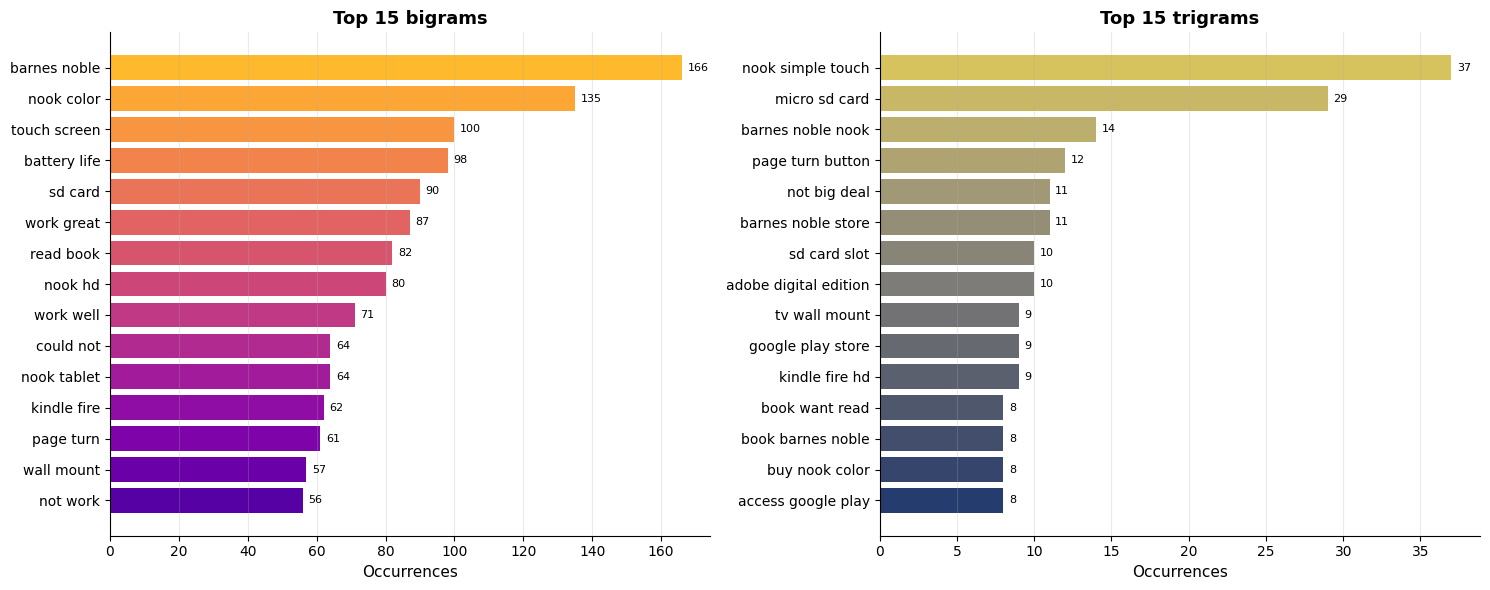

Strongest collocations (count >= 5):
             bigram  count   PMI
         jelly bean      5 13.61
       rand mcnally      7 13.20
         tom sawyer      5 12.35
          dual core      5 11.95
        acer aspire      8 11.74
            kit kat      6 11.67
         angry bird     19 11.61
           pen loop      5 11.47
        form factor      5 11.11
     headphone jack      6 11.00
        third party      5 10.95
pleasantly surprise      7 10.83


In [34]:
def ngrams(tokens, n):
    return zip(*[tokens[i:] for i in range(n)])

bigram_counts = Counter(" ".join(g) for toks in df["tokens"] for g in ngrams(toks, 2))
trigram_counts = Counter(" ".join(g) for toks in df["tokens"] for g in ngrams(toks, 3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, counter, title, cmap, n_show in [
        (axes[0], bigram_counts, "Top 15 bigrams", plt.cm.plasma, 15),
        (axes[1], trigram_counts, "Top 15 trigrams", plt.cm.cividis, 15)]:
    items = counter.most_common(n_show)
    labels, vals = zip(*items)
    ax.barh(labels[::-1], vals[::-1], color=cmap(np.linspace(0.85, 0.15, n_show))[::-1])
    for y_pos, v in enumerate(vals[::-1]):
        ax.text(v + max(vals) * 0.01, y_pos, str(v), va="center", fontsize=8)
    ax.set_title(title); ax.set_xlabel("Occurrences"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

# PMI collocations
total_uni, total_bi = sum(word_counts.values()), sum(bigram_counts.values())
rows = []
for bg, c in bigram_counts.items():
    if c >= 5:
        w1, w2 = bg.split()
        pmi = np.log2((c / total_bi) / ((word_counts[w1] / total_uni) * (word_counts[w2] / total_uni)))
        rows.append((bg, c, round(pmi, 2)))
pmi_df = pd.DataFrame(rows, columns=["bigram", "count", "PMI"]).sort_values("PMI", ascending=False)
print("Strongest collocations (count >= 5):")
print(pmi_df.head(12).to_string(index=False))

**Reading the n-gram results.**

Common phrases mostly identify products and features, such as “nook color,” “battery life,” and “touch screen.” PMI also surfaces technical names and terms, while “pleasantly surprised” is a clear positive phrase. Overall, n-grams add context, but mostly describe what customers reviewed rather than how they felt.

### 1.6 Summary of the NLP findings

Reviews mainly discuss products and features such as e-readers, tablets, screens, and batteries. Overall sentiment is mostly positive, but lower-rated reviews tend to be longer and include more negation, service-related terms, and expressions of frustration.

These findings are limited by the small number of negative reviews and the dataset’s product mix. Word frequency alone does not establish sentiment, and preprocessing choices can affect which patterns appear.

# Part 2: Time Series

**Goal.** Study how review activity and ratings change over time, test stationarity, and forecast **monthly review volume**.



## 2.1 Datetime conversion and date checks


In [35]:
df = pd.read_csv("amazon_reviews_lab.csv")
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

print("Unparseable / missing timestamps:", int(df["timestamp"].isna().sum()))
print("Missing ratings:", int(df["rating"].isna().sum()))
df = df.dropna(subset=["timestamp", "rating"]).copy()

first_ts, last_ts = df["timestamp"].min(), df["timestamp"].max()
print(f"Earliest review: {first_ts.date()}  |  latest review: {last_ts.date()}  |  span: {(last_ts - first_ts).days / 365.25:.1f} years")

by_year = df.groupby(df["timestamp"].dt.year).agg(reviews=("rating", "size"), mean_rating=("rating", "mean")).round(2)
print("\nReviews and mean rating by calendar year:")
print(by_year.to_string())

Unparseable / missing timestamps: 0
Missing ratings: 0
Earliest review: 2000-05-12  |  latest review: 2014-07-17  |  span: 14.2 years

Reviews and mean rating by calendar year:
           reviews  mean_rating
timestamp                      
2000             1         2.00
2002             1         5.00
2005             2         1.00
2007             1         5.00
2008             3         4.00
2009             9         4.22
2010           131         3.91
2011           164         3.88
2012           200         4.14
2013           325         4.30
2014           160         4.25


The data spans 2000–2014, but coverage is extremely uneven: only a handful of reviews exist before 2010, and most come from 2010–2014. Only 17 reviews pre-date 2010 (one or two per year), while 2010–2013 have 131, 164, 200 and 325 reviews (2014 has 160 up to 17 July). A monthly series over the full span would be mostly empty months (the next step counts 103 of 171), which is not a sound basis for time-series modelling. Mean rating by year is 3.91 (2010), 3.88 (2011), 4.14 (2012), 4.30 (2013) and 4.25 (2014), the first hint that ratings drift upward.

## 2.2 Monthly aggregation

The data is grouped by calendar month to calculate review counts and average ratings. The incomplete final month is excluded to avoid a misleading drop, and analysis begins after the last month with no reviews. Months with no reviews have a count of zero and no average rating.

In [36]:
monthly = (df.set_index("timestamp")
             .resample("MS")
             .agg(review_count=("rating", "size"), avg_rating=("rating", "mean")))
monthly_review_count = monthly["review_count"]
monthly_avg_rating = monthly["avg_rating"]
print(f"Months between first and last review: {len(monthly)} | months with zero reviews: {int((monthly_review_count == 0).sum())}")

# 1) drop an incomplete final month
month_end = last_ts + pd.offsets.MonthEnd(0)
partial_last_month = last_ts.normalize() < month_end.normalize()
monthly_complete = monthly.iloc[:-1] if partial_last_month else monthly
if partial_last_month:
    print(f"Excluded incomplete final month {monthly.index[-1].strftime('%Y-%m')} "
          f"({int(monthly.iloc[-1]['review_count'])} reviews up to {last_ts.date()}).")

# 2) analysis window = everything after the last month with zero reviews
empty_positions = np.flatnonzero((monthly_complete["review_count"] == 0).to_numpy())
start_pos = int(empty_positions.max()) + 1 if len(empty_positions) else 0
ts_window = monthly_complete.iloc[start_pos:]
print(f"Analysis window: {ts_window.index[0].strftime('%Y-%m')} to {ts_window.index[-1].strftime('%Y-%m')} "
      f"({len(ts_window)} consecutive months, all with at least one review)")
print(f"Reviews outside the window (too sparse to analyse by month): "
      f"{int(monthly_complete['review_count'].iloc[:start_pos].sum())}")
print("\nMonthly count summary inside the window:")
print(ts_window["review_count"].describe().round(1).to_string())

Months between first and last review: 171 | months with zero reviews: 103
Excluded incomplete final month 2014-07 (13 reviews up to 2014-07-17).
Analysis window: 2009-12 to 2014-06 (55 consecutive months, all with at least one review)
Reviews outside the window (too sparse to analyse by month): 13

Monthly count summary inside the window:
count    55.0
mean     17.7
std       9.9
min       3.0
25%      10.5
50%      16.0
75%      22.5
max      46.0


## 2.3 Monthly review volume and ratings

- **Volume chart:** bars inside the analysis window are teal; sparse earlier months (if any) are grey. The shaded region marks the window used for modelling.
- **Rating charts:** the top panel is the raw monthly mean rating, with marker size proportional to the number of reviews behind each point (months with few reviews are unreliable). The bottom panel adds a **3-month rolling average**, which replaces each month by the mean of that month and the two before it. Smoothing reduces month-to-month noise so that slower movements become visible, at the price of lagging behind real changes and blurring short spikes. Because it averages monthly means, it does not weight months by the number of reviews.

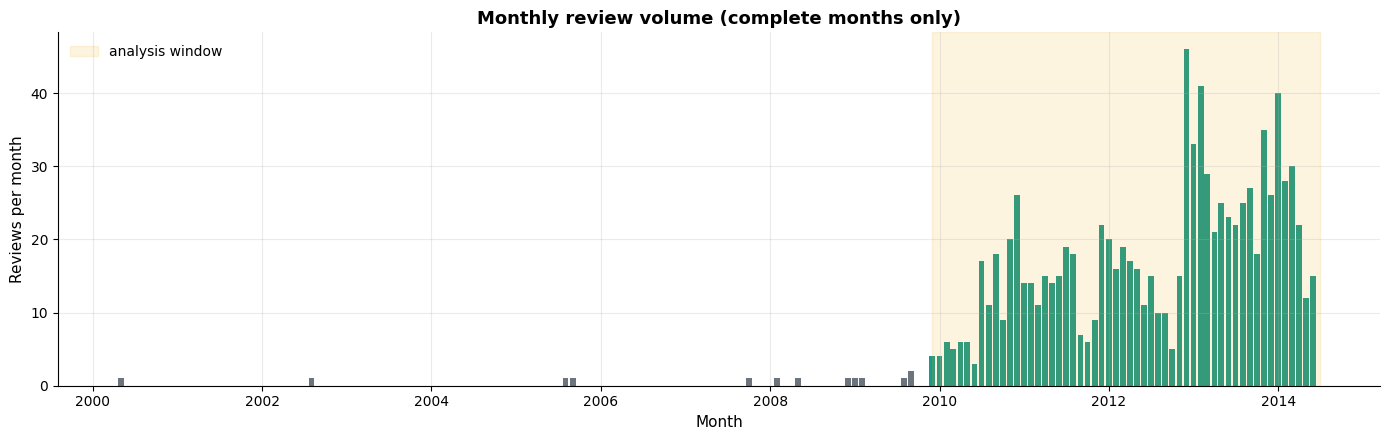

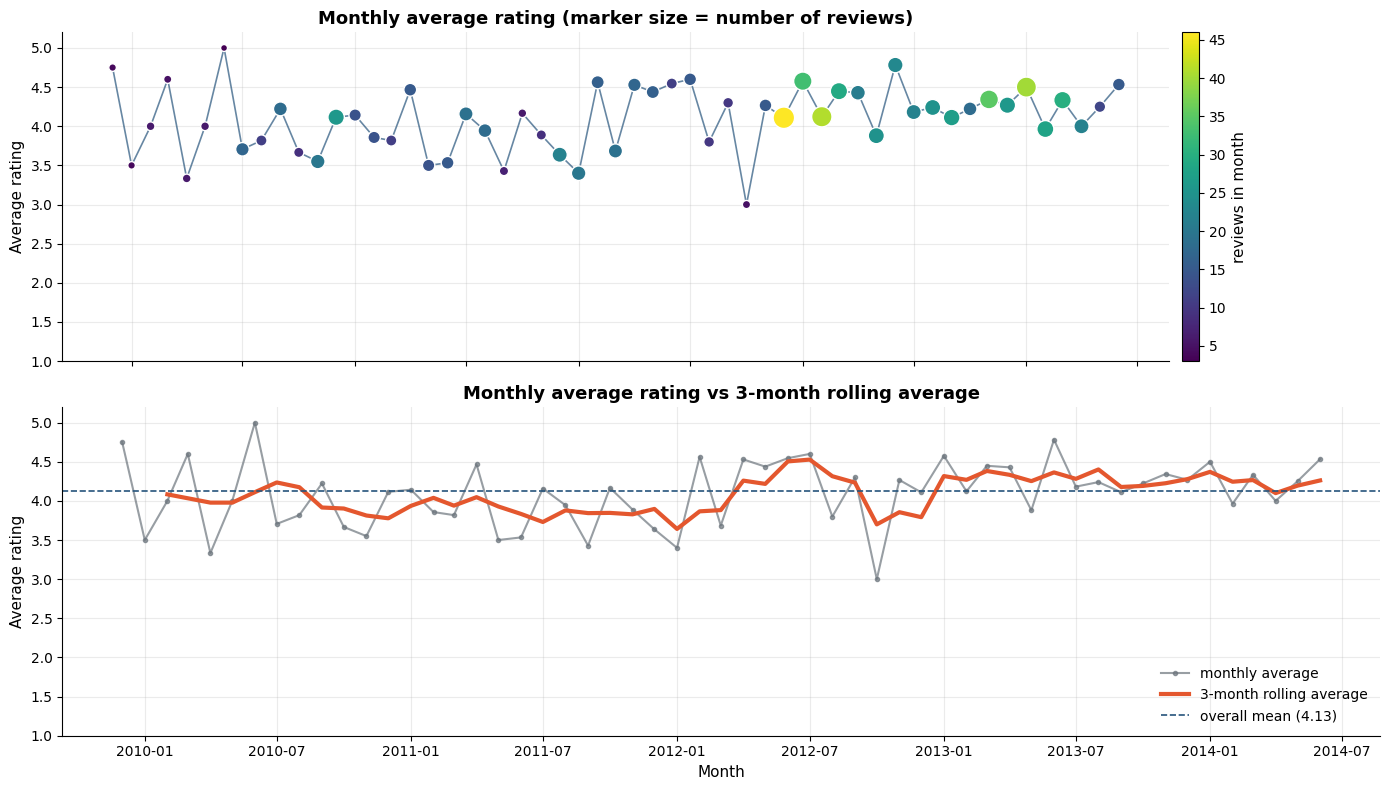

Std. dev. of monthly average rating: raw = 0.42, 3-month rolling = 0.22
Linear trend in monthly average rating: +0.08 stars per year (unweighted, descriptive only)
Busiest month: 2012-12 (46 reviews)


In [37]:
fig, ax = plt.subplots(figsize=(14, 4.5))
in_window = monthly_complete.index >= ts_window.index[0]
ax.bar(monthly_complete.index, monthly_complete["review_count"], width=25,
       color=np.where(in_window, PALETTE["teal"], PALETTE["grey"]))
ax.axvspan(ts_window.index[0], ts_window.index[-1] + pd.offsets.MonthEnd(0), color=PALETTE["gold"], alpha=0.12,
           label="analysis window")
ax.set_title("Monthly review volume (complete months only)")
ax.set_xlabel("Month"); ax.set_ylabel("Reviews per month"); ax.legend()
plt.tight_layout(); plt.show()

rating_w = ts_window["avg_rating"]
rolling_3 = rating_w.rolling(window=3, min_periods=3).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(rating_w.index, rating_w, color=PALETTE["navy"], lw=1.2, alpha=0.7)
sc = axes[0].scatter(rating_w.index, rating_w, s=ts_window["review_count"] * 5 + 10,
                     c=ts_window["review_count"], cmap="viridis", edgecolor="white", zorder=3)
fig.colorbar(sc, ax=axes[0], label="reviews in month", pad=0.01)
axes[0].set_title("Monthly average rating (marker size = number of reviews)")
axes[0].set_ylabel("Average rating"); axes[0].set_ylim(1, 5.2)

axes[1].plot(rating_w.index, rating_w, color=PALETTE["grey"], lw=1.5, alpha=0.7, marker="o", ms=3, label="monthly average")
axes[1].plot(rolling_3.index, rolling_3, color=PALETTE["coral"], lw=3, label="3-month rolling average")
axes[1].axhline(df["rating"].mean(), color=PALETTE["navy"], ls="--", lw=1.2, label=f"overall mean ({df['rating'].mean():.2f})")
axes[1].set_title("Monthly average rating vs 3-month rolling average")
axes[1].set_xlabel("Month"); axes[1].set_ylabel("Average rating"); axes[1].set_ylim(1, 5.2); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

x = np.arange(len(rating_w))
slope = np.polyfit(x, rating_w.to_numpy(), 1)[0]
print(f"Std. dev. of monthly average rating: raw = {rating_w.std():.2f}, 3-month rolling = {rolling_3.std():.2f}")
print(f"Linear trend in monthly average rating: {slope * 12:+.2f} stars per year (unweighted, descriptive only)")
print(f"Busiest month: {ts_window['review_count'].idxmax().strftime('%Y-%m')} ({int(ts_window['review_count'].max())} reviews)")

From December 2009 to June 2014, monthly review volume generally increased, though the dataset cannot show whether this reflects real activity or how the sample was collected. Average ratings were mostly high, with a slight upward trend, but monthly fluctuations—especially in months with few reviews—make that pattern uncertain.



## 2.4 Train/test split and stationarity

The last 12 months are reserved for testing, while stationarity tests and model choices use training data only. The section explains the ADF and KPSS tests, whose null hypotheses differ, and checks rolling statistics plus log, first-difference, and seasonal-difference transformations.

Train: 2009-12 to 2013-06 (43 months)
Test : 2013-07 to 2014-06 (12 months)


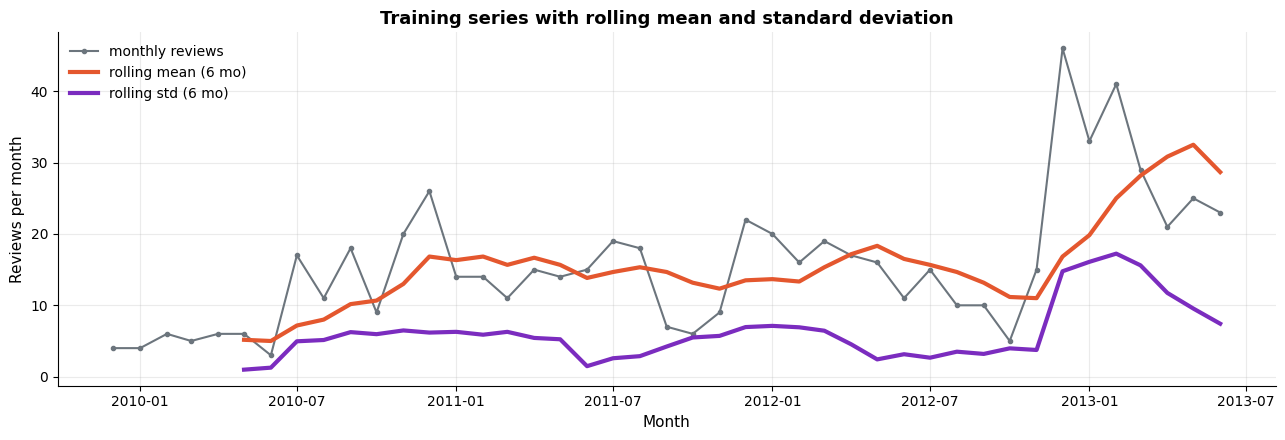

                           n  ADF stat   ADF p  KPSS stat  KPSS p ADF verdict (5%) KPSS verdict (5%)
series                                                                                              
raw counts                43    -3.067  0.0291      0.584   0.024       stationary    non-stationary
log(1+count)              43    -3.152  0.0229      0.619   0.021       stationary    non-stationary
first difference          42    -3.022  0.0329      0.042   0.100       stationary        stationary
first difference of log   42    -2.874  0.0485      0.080   0.100       stationary        stationary
seasonal difference (12)  31     0.465  0.9838      0.170   0.100   non-stationary        stationary

ADF null hypothesis: the series has a unit root (non-stationary).
Raw training series: ADF p = 0.0291 -> reject H0 (evidence of stationarity)
Rule used: d = 0 if ADF p < 0.05 on the raw training series, otherwise d = 1  ->  d = 0
KPSS cross-check on raw series: non-stationary (disagrees with

In [38]:
try:
    from statsmodels.tsa.stattools import adfuller, kpss
    from statsmodels.tsa.arima.model import ARIMA
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    from statsmodels.tsa.seasonal import seasonal_decompose
    from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
    from statsmodels.stats.diagnostic import acorr_ljungbox
except ImportError as exc:
    raise ImportError("Part 2 needs the 'statsmodels' package. Install it yourself with "
                      "`pip install statsmodels` (this notebook does not install anything automatically).") from exc

warnings.filterwarnings("ignore", category=FutureWarning)

y = ts_window["review_count"].astype(float)
H = 12                                         # forecast horizon = size of the test set
train, test = y.iloc[:-H], y.iloc[-H:]
print(f"Train: {train.index[0]:%Y-%m} to {train.index[-1]:%Y-%m} ({len(train)} months)")
print(f"Test : {test.index[0]:%Y-%m} to {test.index[-1]:%Y-%m} ({len(test)} months)")

# rolling statistics (training data)
roll_mean, roll_std = train.rolling(6).mean(), train.rolling(6).std()
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(train.index, train, color=PALETTE["grey"], marker="o", ms=3, label="monthly reviews")
ax.plot(roll_mean.index, roll_mean, color=PALETTE["coral"], lw=3, label="rolling mean (6 mo)")
ax.plot(roll_std.index, roll_std, color=PALETTE["purple"], lw=3, label="rolling std (6 mo)")
ax.set_title("Training series with rolling mean and standard deviation")
ax.set_xlabel("Month"); ax.set_ylabel("Reviews per month"); ax.legend()
plt.tight_layout(); plt.show()

#ADF and KPSS on several versions of the training series
def stationarity_row(series, label):
    s = series.dropna()
    adf_stat, adf_p, *_ = adfuller(s, autolag="AIC")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")        # KPSS warns when p is outside its lookup table
        kpss_stat, kpss_p, *_ = kpss(s, regression="c", nlags="auto")
    return {"series": label, "n": len(s), "ADF stat": round(adf_stat, 3), "ADF p": round(adf_p, 4),
            "KPSS stat": round(kpss_stat, 3), "KPSS p": round(kpss_p, 3)}

log_train = np.log1p(train)
versions = [("raw counts", train), ("log(1+count)", log_train),
            ("first difference", train.diff()), ("first difference of log", log_train.diff()),
            ("seasonal difference (12)", train.diff(12))]
stationarity = pd.DataFrame([stationarity_row(s, lbl) for lbl, s in versions]).set_index("series")
stationarity["ADF verdict (5%)"] = np.where(stationarity["ADF p"] < 0.05, "stationary", "non-stationary")
stationarity["KPSS verdict (5%)"] = np.where(stationarity["KPSS p"] < 0.05, "non-stationary", "stationary")
print(stationarity.to_string())

# differencing order chosen from the RAW training series by the ADF rule
d_order = 0 if stationarity.loc["raw counts", "ADF p"] < 0.05 else 1
print(f"\nADF null hypothesis: the series has a unit root (non-stationary).")
print(f"Raw training series: ADF p = {stationarity.loc['raw counts', 'ADF p']:.4f} -> "
      f"{'reject H0 (evidence of stationarity)' if d_order == 0 else 'cannot reject H0 (treat as non-stationary)'}")
print(f"Rule used: d = 0 if ADF p < 0.05 on the raw training series, otherwise d = 1  ->  d = {d_order}")
kpss_raw = stationarity.loc["raw counts", "KPSS verdict (5%)"]
print(f"KPSS cross-check on raw series: {kpss_raw} "
      f"({'agrees' if (kpss_raw == 'stationary') == (d_order == 0) else 'disagrees'} with ADF)")

Stationarity tests give mixed results for the raw review counts: ADF suggests stationarity, while KPSS suggests a trend or level shift. Both tests support stationarity after first differencing. The analysis follows its stated rule and uses the raw counts, but notes that choosing first differences would also have been reasonable.

## 2.5 ACF/PACF and seasonal decomposition

ACF and PACF plots help suggest a small set of candidate AR and MA models, but the short series makes those patterns uncertain. Seasonal decomposition is included as an exploratory check; because each month of the year has only a few observations, any apparent seasonal pattern should be treated cautiously.

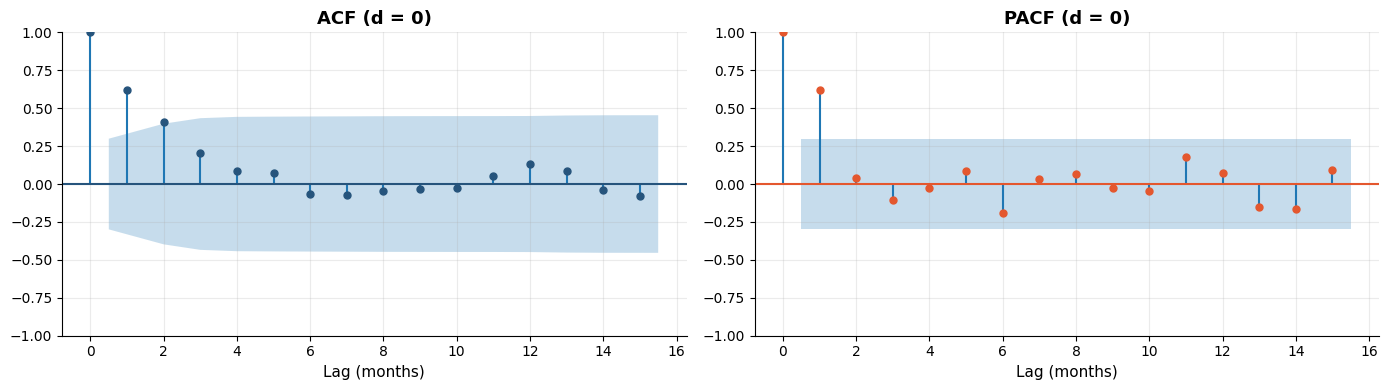

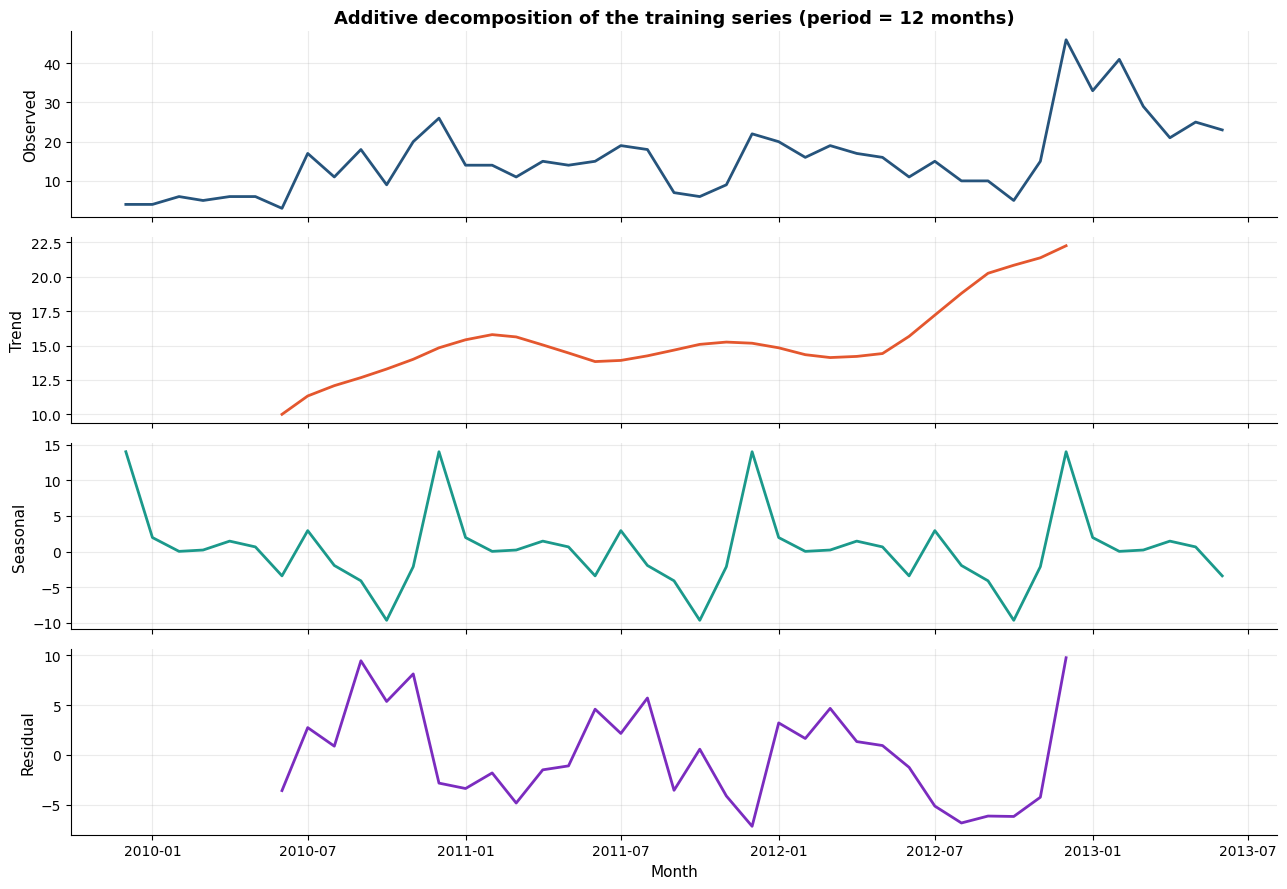

Seasonal strength = 0.59 (moderate; rule of thumb: <0.3 weak, 0.3-0.6 moderate, >0.6 strong)
Highest seasonal index: month 12 (+14.0); lowest: month 10 (-9.6)
Caution: seasonal indices rest on only 3-4 observations per month; treat as exploratory.


In [39]:
acf_series = train.diff().dropna() if d_order == 1 else train
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(acf_series, lags=15, ax=axes[0], color=PALETTE["navy"], title=f"ACF (d = {d_order})")
plot_pacf(acf_series, lags=15, ax=axes[1], color=PALETTE["coral"], title=f"PACF (d = {d_order})")
for ax in axes:
    ax.set_xlabel("Lag (months)")
plt.tight_layout(); plt.show()

decomp = seasonal_decompose(train, model="additive", period=12)
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
for ax, (name, comp, col) in zip(axes, [("Observed", decomp.observed, PALETTE["navy"]),
                                         ("Trend", decomp.trend, PALETTE["coral"]),
                                         ("Seasonal", decomp.seasonal, PALETTE["teal"]),
                                         ("Residual", decomp.resid, PALETTE["purple"])]):
    ax.plot(comp.index, comp, color=col, lw=2)
    ax.set_ylabel(name)
axes[0].set_title("Additive decomposition of the training series (period = 12 months)")
axes[-1].set_xlabel("Month")
plt.tight_layout(); plt.show()

resid_s = decomp.resid.dropna()
seas_s = decomp.seasonal.loc[resid_s.index]
seasonal_strength = max(0.0, 1 - resid_s.var() / (seas_s + resid_s).var())
label = "weak" if seasonal_strength < 0.3 else ("moderate" if seasonal_strength < 0.6 else "strong")
print(f"Seasonal strength = {seasonal_strength:.2f} ({label}; rule of thumb: <0.3 weak, 0.3-0.6 moderate, >0.6 strong)")
peak_m = decomp.seasonal.groupby(decomp.seasonal.index.month).mean()
print(f"Highest seasonal index: month {int(peak_m.idxmax())} ({peak_m.max():+.1f}); lowest: month {int(peak_m.idxmin())} ({peak_m.min():+.1f})")
print("Caution: seasonal indices rest on only 3-4 observations per month; treat as exploratory.")

**Reading the ACF/PACF and decomposition.**

- **ACF/PACF** (shown for the undifferenced series because d = 0) are used only to motivate the small candidate set of AR(1), AR(2), MA(1), MA(2) and ARMA(1,1); with 43 points the confidence bands are wide.
- **Seasonal strength is 0.59, "moderate"** – just below the 0.6 rule-of-thumb threshold for "strong". The seasonal component is highest in December (+14.0 reviews relative to trend) and lowest in October (−9.6). Averaging the raw counts by calendar month points the same way (December 24.8, January 22.2, February 21.0 versus October 9.5), but that comparison is also affected by the upward trend: the window ends in June 2014, so January–June each include a high-volume 2014 month while July–December do not.
- **How far to trust it.** Each calendar month rests on only 3–4 observations, and a single large December (46 reviews in 2012) can dominate the December index. A winter peak could plausibly reflect gift-season purchases of e-readers and tablets, but nothing in this file tests that explanation, so it is a hypothesis only. The out-of-sample results below also do not support a useful seasonal forecast: the seasonal-naive forecast was the *worst* of all models.

## 2.6 Forecast model comparison

The candidates include three simple baselines, several low-order ARIMA models, and one seasonal experiment. ARIMA order is selected by AICc on training data; all models are then compared on the held-out test period using MAE and RMSE, with MAPE only if every actual value is positive.

In [40]:
def forecast_metrics(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    err = actual - pred
    mape = np.mean(np.abs(err / actual)) * 100 if (actual > 0).all() else np.nan   # undefined with zeros
    return {"MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err ** 2)), "MAPE %": mape}

trend = "c" if d_order == 0 else "n"
forecasts = {}                                   # name -> (mean, lower, upper)
ic_rows = []

# baselines
forecasts["Naive (last value)"] = (pd.Series(train.iloc[-1], index=test.index), None, None)
forecasts["Seasonal naive (t-12)"] = (pd.Series(train.iloc[-12:].to_numpy(), index=test.index), None, None)
forecasts["Mean of training"] = (pd.Series(train.mean(), index=test.index), None, None)

# ARIMA candidates (fit on training data only)
fitted = {}
for p, q in [(1, 0), (2, 0), (0, 1), (0, 2), (1, 1)]:
    order = (p, d_order, q)
    name = f"ARIMA{order}"
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = ARIMA(train, order=order, trend=trend).fit()
        fitted[name] = (order, res)
        fc = res.get_forecast(steps=H)
        ci = fc.conf_int(alpha=0.05)
        forecasts[name] = (pd.Series(np.asarray(fc.predicted_mean), index=test.index),
                           pd.Series(np.asarray(ci.iloc[:, 0]), index=test.index),
                           pd.Series(np.asarray(ci.iloc[:, 1]), index=test.index))
        ic_rows.append({"model": name, "AIC": res.aic, "AICc": res.aicc, "BIC": res.bic})
    except Exception as exc:
        print(f"  {name} could not be fitted: {type(exc).__name__}: {exc}")

ic_table = pd.DataFrame(ic_rows).set_index("model").sort_values("AICc")
print("Information criteria on training data (lower is better; comparable because d is fixed):")
print(ic_table.round(1).to_string())
best_name = ic_table["AICc"].idxmin()
best_order, best_res = fitted[best_name]
print(f"\nSelected by AICc: {best_name}   |   lowest BIC: {ic_table['BIC'].idxmin()}")

# seasonal experiment
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        sres = SARIMAX(train, order=(0, d_order, 1), seasonal_order=(0, 1, 0, 12), trend=trend if d_order == 0 else None,
                       enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    sfc = sres.get_forecast(steps=H)
    sci = sfc.conf_int(alpha=0.05)
    sname = f"SARIMA(0,{d_order},1)(0,1,0,12) [experimental]"
    forecasts[sname] = (pd.Series(np.asarray(sfc.predicted_mean), index=test.index),
                        pd.Series(np.asarray(sci.iloc[:, 0]), index=test.index),
                        pd.Series(np.asarray(sci.iloc[:, 1]), index=test.index))
except Exception as exc:
    print(f"Seasonal SARIMA experiment skipped: {type(exc).__name__}: {exc}")

# test-set evaluation
results = pd.DataFrame({name: forecast_metrics(test, f[0]) for name, f in forecasts.items()}).T
results["selected by AICc"] = ["<-- selected ARIMA" if n == best_name else "" for n in results.index]
print("\nTest-set accuracy (last 12 months; lower is better):")
print(results.round(2).sort_values("RMSE").to_string())
print(f"\nMean monthly count in the test period: {test.mean():.1f}  (errors above are in reviews per month)")

Information criteria on training data (lower is better; comparable because d is fixed):
                  AIC   AICc    BIC
model                              
ARIMA(1, 0, 0)  298.5  299.2  303.8
ARIMA(2, 0, 0)  300.3  301.4  307.4
ARIMA(0, 0, 2)  300.4  301.4  307.4
ARIMA(1, 0, 1)  300.4  301.4  307.4
ARIMA(0, 0, 1)  306.0  306.6  311.3

Selected by AICc: ARIMA(1, 0, 0)   |   lowest BIC: ARIMA(1, 0, 0)

Test-set accuracy (last 12 months; lower is better):
                                          MAE   RMSE  MAPE %    selected by AICc
Naive (last value)                       6.33   7.90   27.85                    
ARIMA(2, 0, 0)                           8.86  11.31   30.97                    
ARIMA(1, 0, 1)                           8.90  11.35   31.14                    
ARIMA(1, 0, 0)                           9.11  11.52   31.94  <-- selected ARIMA
ARIMA(0, 0, 2)                           9.37  11.80   32.99                    
ARIMA(0, 0, 1)                           9.96  12.07 

### Diagnostics, forecast plot and future outlook

For the selected model we check the residuals with the **Ljung-Box test** (H0: residuals are uncorrelated white noise; a small p-value means the model has left structure unexplained). We then plot the held-out actuals against the baselines and the ARIMA forecast with its **95% prediction interval**, and report how many actual months fell inside that interval. Finally the chosen specification is refitted on all available months to give an *illustrative* six-month outlook.

Ljung-Box (lag 10) on ARIMA(1, 0, 0) residuals: p = 0.937 -> no significant leftover autocorrelation


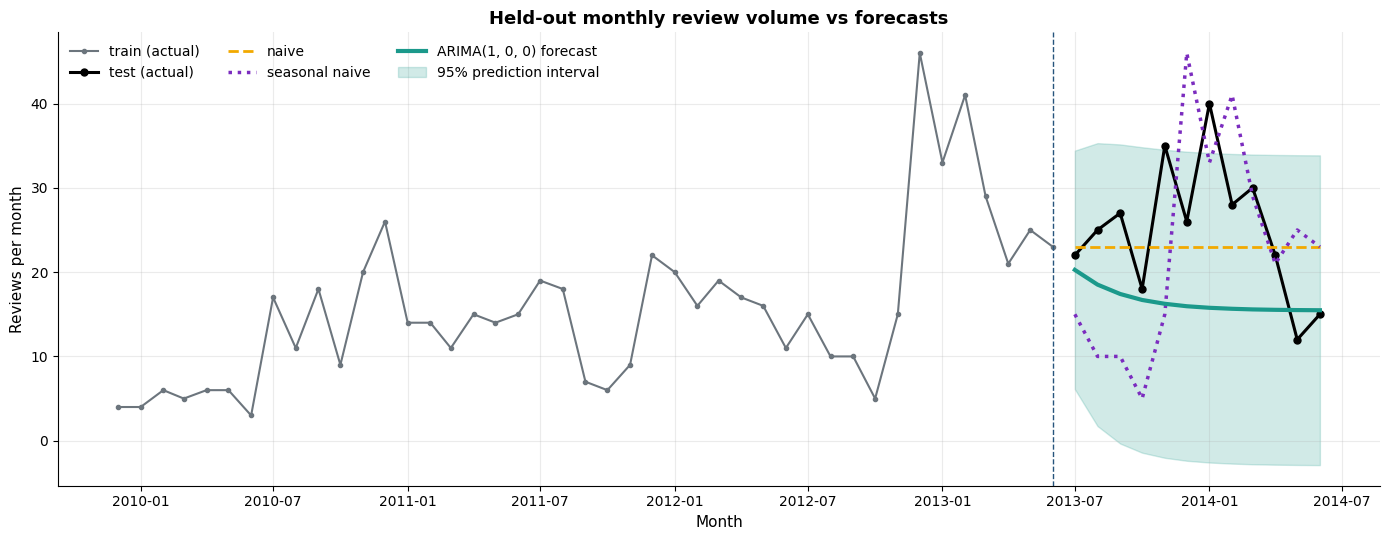

83% of the 12 test months fall inside the 95% interval; average interval width = 35.6 reviews (vs mean actual 25.0).


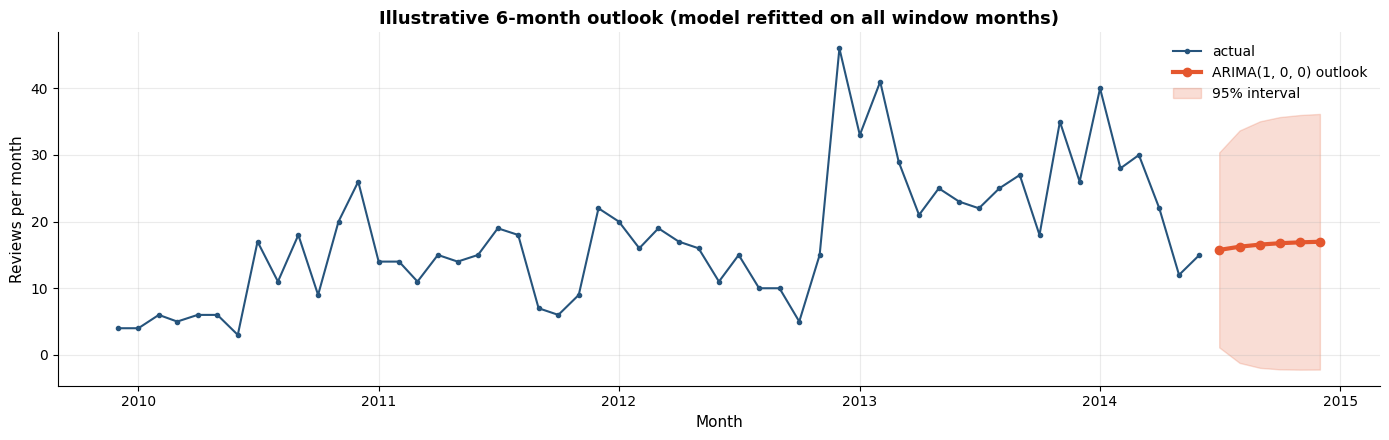

In [41]:
resid = pd.Series(np.asarray(best_res.resid))[d_order:]          # first d residuals are a start-up artefact
lb = acorr_ljungbox(resid, lags=[10], return_df=True)
lb_p = float(lb["lb_pvalue"].iloc[0])
print(f"Ljung-Box (lag 10) on {best_name} residuals: p = {lb_p:.3f} -> "
      f"{'no significant leftover autocorrelation' if lb_p > 0.05 else 'residual autocorrelation remains'}")

mean_f, lo_f, hi_f = forecasts[best_name]
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(train.index, train, color=PALETTE["grey"], marker="o", ms=3, label="train (actual)")
ax.plot(test.index, test, color="black", marker="o", ms=5, lw=2.2, label="test (actual)")
ax.plot(test.index, forecasts["Naive (last value)"][0], color=PALETTE["gold"], ls="--", lw=2, label="naive")
ax.plot(test.index, forecasts["Seasonal naive (t-12)"][0], color=PALETTE["purple"], ls=":", lw=2.5, label="seasonal naive")
ax.plot(test.index, mean_f, color=PALETTE["teal"], lw=3, label=f"{best_name} forecast")
ax.fill_between(test.index, lo_f, hi_f, color=PALETTE["teal"], alpha=0.2, label="95% prediction interval")
ax.axvline(train.index[-1], color=PALETTE["navy"], ls="--", lw=1)
ax.set_title("Held-out monthly review volume vs forecasts")
ax.set_xlabel("Month"); ax.set_ylabel("Reviews per month"); ax.legend(ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

inside = ((test >= lo_f) & (test <= hi_f)).mean()
print(f"{inside:.0%} of the 12 test months fall inside the 95% interval; "
      f"average interval width = {(hi_f - lo_f).mean():.1f} reviews (vs mean actual {test.mean():.1f}).")

# illustrative outlook: refit selected specification on all complete months in the window
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    full_res = ARIMA(y, order=best_order, trend=trend).fit()
future_fc = full_res.get_forecast(steps=6)
future_idx = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=6, freq="MS")
future_mean = pd.Series(np.asarray(future_fc.predicted_mean), index=future_idx)
fci = future_fc.conf_int(alpha=0.05)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(y.index, y, color=PALETTE["navy"], marker="o", ms=3, label="actual")
ax.plot(future_idx, future_mean, color=PALETTE["coral"], lw=3, marker="o", label=f"{best_name} outlook")
ax.fill_between(future_idx, np.asarray(fci.iloc[:, 0]), np.asarray(fci.iloc[:, 1]), color=PALETTE["coral"], alpha=0.2, label="95% interval")
ax.set_title("Illustrative 6-month outlook (model refitted on all window months)")
ax.set_xlabel("Month"); ax.set_ylabel("Reviews per month"); ax.legend()
plt.tight_layout(); plt.show()

### 2.7 Results and interpretation

**Model comparison (training-set criteria).** AR(1) with a constant, ARIMA(1,0,0), has the lowest AICc (299.2) and the lowest BIC (303.8). The next-best models (ARIMA(2,0,0), (0,0,2) and (1,0,1)) have AICc about 301.4, roughly 2 points higher, so the extra parameters bring no real gain, and ARIMA(0,0,1) is clearly the weakest (306.6). Information criteria were therefore consistent with each other, and the simplest competitive model was selected.

**Test-set accuracy (12 held-out months, mean actual volume 25.0 reviews per month).**

| Model | MAE | RMSE | MAPE % |
|---|---|---|---|
| **Naive (last value = 23)** | **6.33** | **7.90** | **27.9** |
| ARIMA(2,0,0) | 8.86 | 11.31 | 31.0 |
| ARIMA(1,0,1) | 8.90 | 11.35 | 31.1 |
| **ARIMA(1,0,0) (selected by AICc)** | 9.11 | 11.52 | 31.9 |
| ARIMA(0,0,2) | 9.37 | 11.80 | 33.0 |
| ARIMA(0,0,1) | 9.96 | 12.07 | 35.5 |
| Mean of training | 10.10 | 12.11 | 36.2 |
| SARIMA(0,0,1)(0,1,0,12), experimental | 10.76 | 12.86 | 50.3 |
| Seasonal naive (t−12) | 11.25 | 12.86 | 49.6 |

The selected ARIMA model did not forecast as well as the simple naive baseline: its RMSE was 11.5 versus 7.9. It struggled to capture the recent rise in review volume, and its prediction intervals were wide and included impossible negative counts. The six-month outlook should therefore be treated as illustrative, not reliable for planning.

## 2.8 Follow-up: differenced (d = 1) candidates
This is an exploratory follow-up because it was added after the d = 0 models underperformed on the test set. It compares first-differenced ARIMA candidates selected by training-set AICc and includes a random-walk-with-drift baseline. Results should be interpreted cautiously because the experiment was post hoc.

In [42]:
#  d = 1 candidates: fit on training data only
d1_forecasts, d1_fitted, d1_ic = {}, {}, []
for p, q in [(0, 1), (1, 0), (1, 1), (0, 2), (2, 0)]:
    order = (p, 1, q)
    name = f"ARIMA{order}"
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = ARIMA(train, order=order, trend="n").fit()
        fc = res.get_forecast(steps=H)
        ci = fc.conf_int(alpha=0.05)
        d1_fitted[name] = (order, res)
        d1_forecasts[name] = (pd.Series(np.asarray(fc.predicted_mean), index=test.index),
                              pd.Series(np.asarray(ci.iloc[:, 0]), index=test.index),
                              pd.Series(np.asarray(ci.iloc[:, 1]), index=test.index))
        d1_ic.append({"model": name, "AIC": res.aic, "AICc": res.aicc, "BIC": res.bic})
    except Exception as exc:
        print(f"  {name} could not be fitted: {type(exc).__name__}: {exc}")

d1_ic_table = pd.DataFrame(d1_ic).set_index("model").sort_values("AICc")
print("d = 1 family - information criteria on training data (comparable within this family only):")
print(d1_ic_table.round(1).to_string())
best_d1_name = d1_ic_table["AICc"].idxmin()
best_d1_order, best_d1_res = d1_fitted[best_d1_name]
print(f"\nSelected within the d = 1 family by AICc: {best_d1_name}   |   lowest BIC: {d1_ic_table['BIC'].idxmin()}")

#random walk with drift baseline
drift = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
d1_forecasts["Random walk with drift"] = (
    pd.Series(train.iloc[-1] + drift * np.arange(1, H + 1), index=test.index), None, None)
print(f"Average monthly change in the training set (drift): {drift:+.2f} reviews per month")

#test-set comparison with everything from section 2.6
d1_results = pd.DataFrame({n: forecast_metrics(test, f[0]) for n, f in d1_forecasts.items()}).T
all_results = pd.concat([results[["MAE", "RMSE", "MAPE %"]].astype(float), d1_results[["MAE", "RMSE", "MAPE %"]]])
all_results["family"] = ["d = 1" if n in d1_forecasts else "d = 0 / baseline" for n in all_results.index]
all_results["note"] = ["<-- selected d = 1 model" if n == best_d1_name else
                       ("<-- selected d = 0 model" if n == best_name else "") for n in all_results.index]
print("\nTest-set accuracy for ALL models (last 12 months; lower is better):")
print(all_results.sort_values("RMSE").round(2).to_string())

d = 1 family - information criteria on training data (comparable within this family only):
                  AIC   AICc    BIC
model                              
ARIMA(1, 1, 1)  293.2  293.8  298.4
ARIMA(0, 1, 1)  294.5  294.8  298.0
ARIMA(1, 1, 0)  295.0  295.3  298.5
ARIMA(0, 1, 2)  295.2  295.8  300.4
ARIMA(2, 1, 0)  296.9  297.5  302.1

Selected within the d = 1 family by AICc: ARIMA(1, 1, 1)   |   lowest BIC: ARIMA(0, 1, 1)
Average monthly change in the training set (drift): +0.45 reviews per month

Test-set accuracy for ALL models (last 12 months; lower is better):
                                          MAE   RMSE  MAPE %            family                      note
ARIMA(0, 1, 2)                           5.94   7.62   28.65             d = 1                          
ARIMA(0, 1, 1)                           6.24   7.77   28.13             d = 1                          
ARIMA(1, 1, 0)                           6.28   7.81   28.08             d = 1                          
A

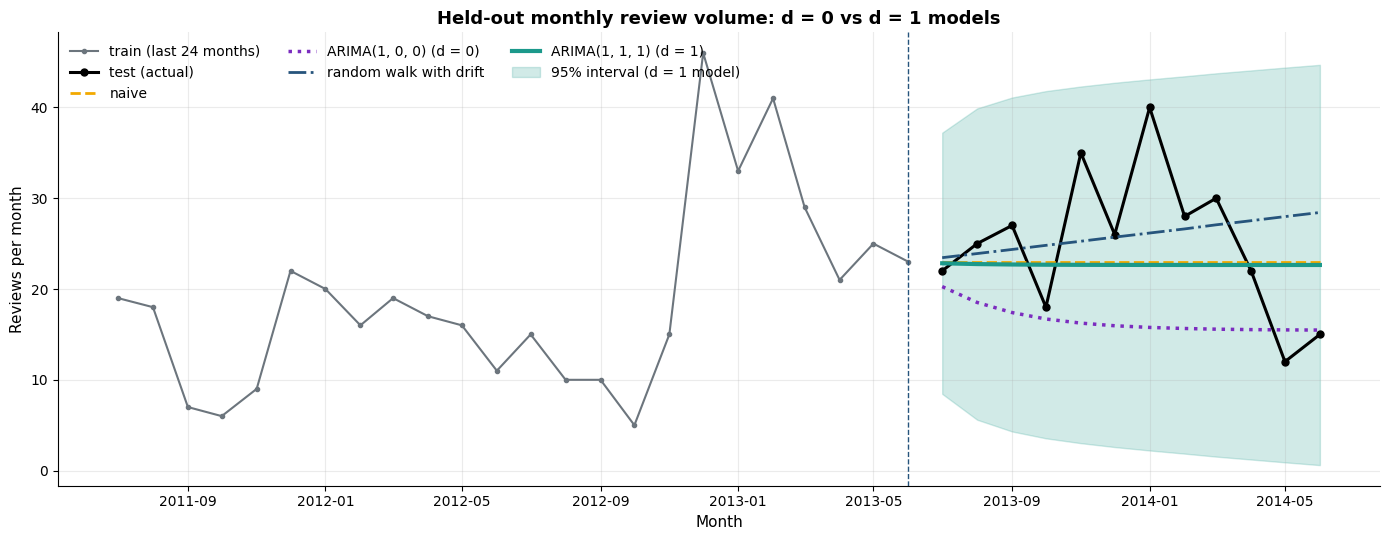

Ljung-Box (lag 10) on ARIMA(1, 1, 1) residuals: p = 0.600
100% of the 12 test months fall inside the 95% interval; average width = 39.4 reviews.

RMSE - ARIMA(1, 1, 1): 7.99 | ARIMA(1, 0, 0): 11.52 | naive: 7.90
The d = 1 model beats the d = 0 model.
The d = 1 model does NOT beat the naive baseline.


In [43]:
# plot: actuals vs naive, selected d = 0 model, selected d = 1 model (with 95% interval), drift
mean_d1, lo_d1, hi_d1 = d1_forecasts[best_d1_name]
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(train.index[-24:], train.iloc[-24:], color=PALETTE["grey"], marker="o", ms=3, label="train (last 24 months)")
ax.plot(test.index, test, color="black", marker="o", ms=5, lw=2.2, label="test (actual)")
ax.plot(test.index, forecasts["Naive (last value)"][0], color=PALETTE["gold"], ls="--", lw=2, label="naive")
ax.plot(test.index, forecasts[best_name][0], color=PALETTE["purple"], ls=":", lw=2.5, label=f"{best_name} (d = 0)")
ax.plot(test.index, d1_forecasts["Random walk with drift"][0], color=PALETTE["navy"], ls="-.", lw=2, label="random walk with drift")
ax.plot(test.index, mean_d1, color=PALETTE["teal"], lw=3, label=f"{best_d1_name} (d = 1)")
ax.fill_between(test.index, lo_d1, hi_d1, color=PALETTE["teal"], alpha=0.2, label="95% interval (d = 1 model)")
ax.axvline(train.index[-1], color=PALETTE["navy"], ls="--", lw=1)
ax.set_title("Held-out monthly review volume: d = 0 vs d = 1 models")
ax.set_xlabel("Month"); ax.set_ylabel("Reviews per month"); ax.legend(ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

d1_resid = pd.Series(np.asarray(best_d1_res.resid))[1:]           # drop the start-up residual
d1_lb_p = float(acorr_ljungbox(d1_resid, lags=[10], return_df=True)["lb_pvalue"].iloc[0])
d1_cover = ((test >= lo_d1) & (test <= hi_d1)).mean()
print(f"Ljung-Box (lag 10) on {best_d1_name} residuals: p = {d1_lb_p:.3f}")
print(f"{d1_cover:.0%} of the 12 test months fall inside the 95% interval; average width = {(hi_d1 - lo_d1).mean():.1f} reviews.")

r_d1, r_d0, r_nv = (all_results.loc[best_d1_name, "RMSE"], all_results.loc[best_name, "RMSE"],
                    all_results.loc["Naive (last value)", "RMSE"])
print(f"\nRMSE - {best_d1_name}: {r_d1:.2f} | {best_name}: {r_d0:.2f} | naive: {r_nv:.2f}")
print("The d = 1 model beats the d = 0 model." if r_d1 < r_d0 else "The d = 1 model does NOT beat the d = 0 model.")
print("The d = 1 model beats the naive baseline." if r_d1 < r_nv else "The d = 1 model does NOT beat the naive baseline.")

The first-differenced ARIMA model forecasts better than the original ARIMA model, but performs about the same as the naive “repeat the latest value” baseline. With only 12 test months and wide prediction intervals, there’s no clear evidence that ARIMA adds useful forecasting value. The post-hoc analysis suggests review volume behaves like a random walk with level shifts.

The 55-month series is small and comes from a limited review sample, so its forecasts are uncertain and do not represent sales or overall platform activity. The d = 1 models perform about as well as the naive baseline, while the d = 0 model performs worse. More complete review histories and rolling-origin evaluation would support a stronger comparison.

# Part 3: Neural Networks

**Goal.** Predict a review's star rating (1–5) from its text with a multilayer perceptron (MLP).

## 3.1 The prediction task and class balance

This is an imbalanced five-class task: most reviews have 5 stars, so accuracy alone may mislead. The analysis also reports per-class metrics, macro-F1, and predictions within one star. It uses cleaned review text and excludes `sentiment_label` because it’s derived from the rating.

In [44]:
if "preprocess_text" not in globals():
    raise RuntimeError("Run Part 1 first: Part 3 re-uses the preprocess_text function defined there.")

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, log_loss)

DATA_PATH = 'amazon_reviews_lab.csv'
df = pd.read_csv(DATA_PATH)
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
df = df.dropna(subset=["rating"]).copy()
df["rating"] = df["rating"].astype(int)
df["review_text"] = df["review_text"].fillna("").astype(str)
df["clean_text"] = df["review_text"].apply(preprocess_text).str.join(" ")

X = df["clean_text"]
y = df["rating"] - 1                      # classes 0..4 (rating 1..5 shifted down by one)
N_CLASSES = 5
CLASS_NAMES = [f"{r} star" for r in range(1, 6)]

counts = y.value_counts().sort_index()
print("Class distribution (rating):", dict(zip(range(1, 6), counts.tolist())))
majority_share = counts.max() / len(y)
print(f"Majority-class baseline accuracy (always predict 5 stars): {majority_share:.1%}")
print(f"Majority-class macro-F1: {f1_score(y, np.full(len(y), counts.idxmax()), average='macro', zero_division=0):.3f}")

Class distribution (rating): {1: 87, 2: 48, 3: 94, 4: 188, 5: 580}
Majority-class baseline accuracy (always predict 5 stars): 58.2%
Majority-class macro-F1: 0.147


## 3.2 Stratified split and TF-IDF features

The data is split into training, validation, and test sets while preserving each rating’s proportion. TF-IDF is fit on training text only to prevent test-data leakage, with the vocabulary limited to reduce overfitting on this small dataset.

In [45]:
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
X_tr, X_val, y_tr, y_val = train_test_split(X_trainval, y_trainval, test_size=0.15, stratify=y_trainval, random_state=SEED)
print(f"Train: {len(X_tr)} | Validation: {len(X_val)} | Test: {len(X_test)}")
print("Test-set class counts:", dict(zip(range(1, 6), np.bincount(y_test, minlength=5).tolist())))

vectorizer = TfidfVectorizer(max_features=3000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr_tfidf = vectorizer.fit_transform(X_tr)             # fit on training text ONLY
Xval_tfidf = vectorizer.transform(X_val)
Xtest_tfidf = vectorizer.transform(X_test)
print(f"TF-IDF matrix (train): {Xtr_tfidf.shape[0]} reviews x {Xtr_tfidf.shape[1]} features, "
      f"{Xtr_tfidf.nnz / Xtr_tfidf.shape[0]:.0f} non-zero features per review on average")

y_tr, y_val, y_test = y_tr.to_numpy(), y_val.to_numpy(), y_test.to_numpy()

Train: 677 | Validation: 120 | Test: 200
Test-set class counts: {1: 17, 2: 10, 3: 19, 4: 38, 5: 116}
TF-IDF matrix (train): 677 reviews x 3000 features, 57 non-zero features per review on average


## 3.3 Neural-network design and training

The notebook uses TensorFlow/Keras when available and falls back to scikit-learn’s "MLPClassifier" otherwise. The saved run used Keras; results may vary slightly across environments.

The MLP uses 3,000 TF-IDF features, ReLU hidden layers, and a five-class softmax output to predict ratings. It trains with cross-entropy loss and the Adam optimizer, using a learning rate of 0.001 and batches of 32 reviews.

To reduce overfitting, the model uses a validation set, early stopping, a limited vocabulary, and regularization through dropout in Keras or an L2 penalty in scikit-learn.
**A small, systematic experiment.** Three configurations are compared **on the validation set only** (macro-F1, then accuracy):

| Config | Hidden layers | Idea |
|---|---|---|
| A | 1 × 64 | simple, small |
| B | 128 → 64 | deeper, with regularisation |
| C | 128 → 64 | as B, plus the minority classes **randomly oversampled** in the training set (validation and test untouched) to counter imbalance |

The best configuration by validation macro-F1 becomes the final model. A TF-IDF **logistic regression** and the majority-class rule serve as simple reference points.

In [20]:
try:
    import tensorflow as tf
    from tensorflow import keras
    BACKEND = "keras"
    tf.keras.utils.set_random_seed(SEED)
except Exception as exc:
    BACKEND = "sklearn"
    print(f"TensorFlow not usable ({type(exc).__name__}); using scikit-learn MLPClassifier instead.")
print("Neural-network backend:", BACKEND)

MAX_EPOCHS, PATIENCE, BATCH = 60, 5, 32

def oversample(Xs, ys, seed=SEED):
    # Randomly repeat minority-class rows until every class matches the largest class.
    rng = np.random.default_rng(seed)
    target = np.bincount(ys).max()
    idx = np.concatenate([rng.choice(np.flatnonzero(ys == c), size=target, replace=True) for c in range(N_CLASSES)])
    rng.shuffle(idx)
    return Xs[idx], ys[idx]

def train_mlp(cfg, Xt, yt, Xv, yv):
    # Returns dict with predict_proba, history and best epoch. Validation data is used for early stopping only.
    if cfg["oversample"]:
        Xt, yt = oversample(Xt, yt)
    if BACKEND == "keras":
        keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
        layers = [keras.layers.Input(shape=(Xt.shape[1],))]
        for units in cfg["hidden"]:
            layers += [keras.layers.Dense(units, activation="relu"), keras.layers.Dropout(cfg["dropout"])]
        layers.append(keras.layers.Dense(N_CLASSES, activation="softmax"))
        model = keras.Sequential(layers)
        model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        h = model.fit(Xt.toarray(), yt, validation_data=(Xv.toarray(), yv), epochs=MAX_EPOCHS,
                      batch_size=BATCH, callbacks=[stop], verbose=0)
        hist = {k: list(v) for k, v in h.history.items()}
        best_epoch = int(np.argmin(hist["val_loss"])) + 1
        return {"predict_proba": lambda M: model.predict(M.toarray(), verbose=0), "history": hist,
                "best_epoch": best_epoch, "model": model}
    #scikit-learn: manual epoch loop so we control validation, early stopping and history
    clf = MLPClassifier(hidden_layer_sizes=cfg["hidden"], activation="relu", solver="adam", alpha=cfg["alpha"],
                        learning_rate_init=1e-3, batch_size=BATCH, random_state=SEED)
    classes = np.arange(N_CLASSES)
    hist = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
    best, best_model, wait = np.inf, None, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        clf.partial_fit(Xt, yt, classes=classes)
        ptr, pva = clf.predict_proba(Xt), clf.predict_proba(Xv)
        hist["loss"].append(log_loss(yt, ptr, labels=classes)); hist["val_loss"].append(log_loss(yv, pva, labels=classes))
        hist["accuracy"].append(accuracy_score(yt, ptr.argmax(1))); hist["val_accuracy"].append(accuracy_score(yv, pva.argmax(1)))
        if hist["val_loss"][-1] < best - 1e-4:
            best, best_model, best_epoch, wait = hist["val_loss"][-1], copy.deepcopy(clf), epoch, 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    return {"predict_proba": best_model.predict_proba, "history": hist, "best_epoch": best_epoch, "model": best_model}

CONFIGS = [
    {"name": "A: 1 hidden layer (64)",          "hidden": (64,),     "dropout": 0.0, "alpha": 1e-4, "oversample": False},
    {"name": "B: 128-64, regularised",          "hidden": (128, 64), "dropout": 0.5, "alpha": 1e-2, "oversample": False},
    {"name": "C: 128-64, regularised + oversampling", "hidden": (128, 64), "dropout": 0.5, "alpha": 1e-2, "oversample": True},
]

runs, rows = {}, []
for cfg in CONFIGS:
    run = train_mlp(cfg, Xtr_tfidf, y_tr, Xval_tfidf, y_val)
    runs[cfg["name"]] = run
    pv = run["predict_proba"](Xval_tfidf).argmax(1)
    rows.append({"config": cfg["name"], "best epoch": run["best_epoch"], "epochs run": len(run["history"]["loss"]),
                 "val accuracy": accuracy_score(y_val, pv), "val macro-F1": f1_score(y_val, pv, average="macro", zero_division=0)})
val_table = pd.DataFrame(rows).set_index("config")
print(val_table.round(3).to_string())

final_name = val_table["val macro-F1"].idxmax()
final_run = runs[final_name]
print(f"\nSelected on validation macro-F1: {final_name}")

Neural-network backend: keras


                                       best epoch  epochs run  val accuracy  val macro-F1
config                                                                                   
A: 1 hidden layer (64)                          9          14         0.592         0.251
B: 128-64, regularised                          6          11         0.583         0.151
C: 128-64, regularised + oversampling           3           8         0.575         0.300

Selected on validation macro-F1: C: 128-64, regularised + oversampling


## 3.4 Learning curves

The learning curves help identify overfitting: it may be happening when training loss keeps decreasing while validation loss rises. Early stopping keeps the best validation weights. If training data is oversampled, its accuracy is not directly comparable to validation accuracy.



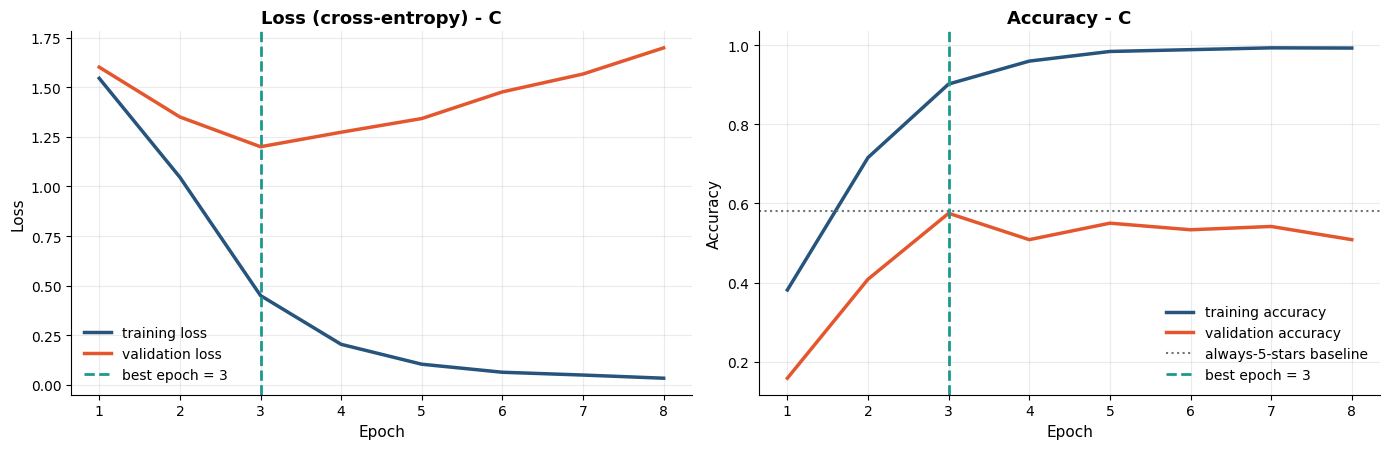

At the kept epoch: train accuracy 0.90, validation accuracy 0.57 (gap +0.33).
Validation loss: lowest 1.200 at epoch 3; final epoch 1.699. Validation loss rose afterwards -> early stopping was needed.


In [21]:
hist, best_ep = final_run["history"], final_run["best_epoch"]
epochs = np.arange(1, len(hist["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].plot(epochs, hist["loss"], color=PALETTE["navy"], lw=2.5, label="training loss")
axes[0].plot(epochs, hist["val_loss"], color=PALETTE["coral"], lw=2.5, label="validation loss")
axes[1].plot(epochs, hist["accuracy"], color=PALETTE["navy"], lw=2.5, label="training accuracy")
axes[1].plot(epochs, hist["val_accuracy"], color=PALETTE["coral"], lw=2.5, label="validation accuracy")
axes[1].axhline(majority_share, color=PALETTE["grey"], ls=":", lw=1.5, label="always-5-stars baseline")
for ax, ttl, yl in [(axes[0], "Loss (cross-entropy)", "Loss"), (axes[1], "Accuracy", "Accuracy")]:
    ax.axvline(best_ep, color=PALETTE["teal"], ls="--", lw=2, label=f"best epoch = {best_ep}")
    ax.set_title(f"{ttl} - {final_name.split(':')[0]}"); ax.set_xlabel("Epoch"); ax.set_ylabel(yl); ax.legend()
plt.tight_layout(); plt.show()

gap = hist["accuracy"][best_ep - 1] - hist["val_accuracy"][best_ep - 1]
print(f"At the kept epoch: train accuracy {hist['accuracy'][best_ep - 1]:.2f}, validation accuracy {hist['val_accuracy'][best_ep - 1]:.2f} (gap {gap:+.2f}).")
print(f"Validation loss: lowest {min(hist['val_loss']):.3f} at epoch {best_ep}; final epoch {hist['val_loss'][-1]:.3f}. "
      f"{'Validation loss rose afterwards -> early stopping was needed.' if hist['val_loss'][-1] > min(hist['val_loss']) + 0.01 else 'No clear rise in validation loss.'}")

## 3.5 Final evaluation on the untouched test set

The selected model predicts the held-out test reviews once. We report accuracy, macro- and weighted-F1, per-class precision/recall/F1 (the classification report), the share of predictions within ±1 star, and two confusion matrices: **counts**, and **row-normalised** (each row sums to 100% – i.e. *recall* for that true rating, which makes the minority classes readable). Reference models (majority rule, TF-IDF logistic regression with default settings, not tuned) are scored on the same test set for context only.

Test accuracy: 0.535 | macro-F1: 0.282 | weighted-F1: 0.484
Within +/-1 star: 80.5% | mean absolute error: 0.78 stars

              precision    recall  f1-score   support

      1 star      0.364     0.235     0.286        17
      2 star      0.167     0.100     0.125        10
      3 star      0.188     0.158     0.171        19
      4 star      0.200     0.079     0.113        38
      5 star      0.632     0.828     0.716       116

    accuracy                          0.535       200
   macro avg      0.310     0.280     0.282       200
weighted avg      0.461     0.535     0.484       200

                                 accuracy  macro-F1
Majority class (always 5 stars)     0.580     0.147
TF-IDF logistic regression          0.580     0.149
MLP (keras) - C                     0.535     0.282


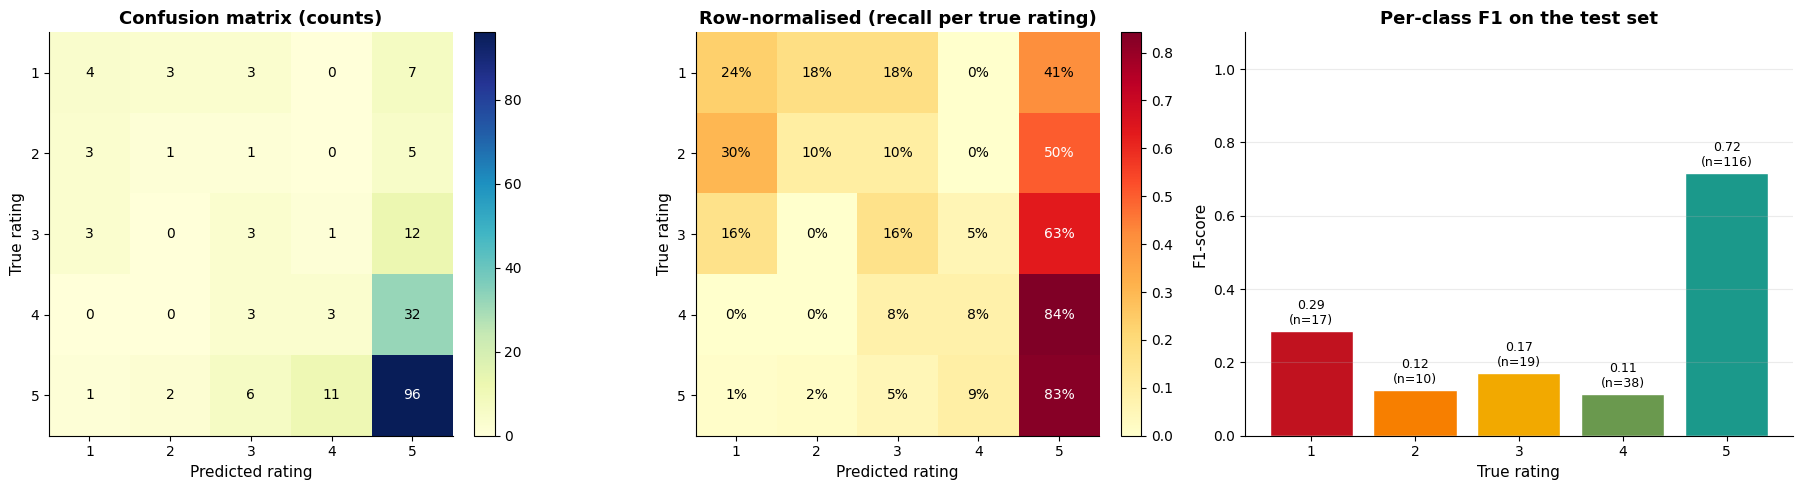

In [22]:
proba_test = final_run["predict_proba"](Xtest_tfidf)
y_pred = proba_test.argmax(1)

acc = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
weighted_f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
within_one = np.mean(np.abs(y_pred - y_test) <= 1)
mae_stars = np.mean(np.abs(y_pred - y_test))
print(f"Test accuracy: {acc:.3f} | macro-F1: {macro_f1:.3f} | weighted-F1: {weighted_f1:.3f}")
print(f"Within +/-1 star: {within_one:.1%} | mean absolute error: {mae_stars:.2f} stars\n")
print(classification_report(y_test, y_pred, labels=range(5), target_names=CLASS_NAMES, zero_division=0, digits=3))

report = pd.DataFrame(classification_report(y_test, y_pred, labels=range(5), target_names=CLASS_NAMES,
                                            zero_division=0, output_dict=True)).T.loc[CLASS_NAMES]

#reference models (scored once on the test set, not used for any decision)
lr = LogisticRegression(max_iter=2000, random_state=SEED).fit(Xtr_tfidf, y_tr)
lr_pred = lr.predict(Xtest_tfidf)
majority_pred = np.full(len(y_test), np.bincount(y_tr).argmax())
compare = pd.DataFrame({
    "accuracy": [accuracy_score(y_test, p) for p in (majority_pred, lr_pred, y_pred)],
    "macro-F1": [f1_score(y_test, p, average="macro", zero_division=0) for p in (majority_pred, lr_pred, y_pred)]},
    index=["Majority class (always 5 stars)", "TF-IDF logistic regression", f"MLP ({BACKEND}) - {final_name.split(':')[0]}"])
print(compare.round(3).to_string())

def plot_cm(ax, matrix, title, cmap, fmt):
    im = ax.imshow(matrix, cmap=cmap, vmin=0, vmax=matrix.max())
    ax.set_xticks(range(5)); ax.set_xticklabels(range(1, 6)); ax.set_yticks(range(5)); ax.set_yticklabels(range(1, 6))
    ax.set_xlabel("Predicted rating"); ax.set_ylabel("True rating"); ax.set_title(title); ax.grid(False)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, format(matrix[i, j], fmt), ha="center", va="center",
                    color="white" if matrix[i, j] > matrix.max() * 0.55 else "black", fontsize=10)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

cm = confusion_matrix(y_test, y_pred, labels=range(5))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
plot_cm(axes[0], cm, "Confusion matrix (counts)", "YlGnBu", "d")
plot_cm(axes[1], cm_norm, "Row-normalised (recall per true rating)", "YlOrRd", ".0%")
axes[2].bar(range(1, 6), report["f1-score"], color=[RATING_COLORS[r] for r in range(1, 6)], edgecolor="white")
for r, (f1v, sup) in enumerate(zip(report["f1-score"], report["support"]), start=1):
    axes[2].text(r, f1v + 0.02, f"{f1v:.2f}\n(n={int(sup)})", ha="center", fontsize=9)
axes[2].set_ylim(0, 1.1); axes[2].set_xlabel("True rating"); axes[2].set_ylabel("F1-score")
axes[2].set_title("Per-class F1 on the test set"); axes[2].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### 3.6 Results and interpretation

**Configuration choice (validation set, 120 reviews).**

| Config | Best epoch | Val. accuracy | Val. macro-F1 |
|---|---|---|---|
| A: 1 hidden layer (64) | 9 | 0.592 | 0.251 |
| B: 128–64, regularised | 6 | 0.583 | 0.151 |
| **C: 128–64, regularised + oversampling** | 3 | 0.575 | **0.300** |

B scored a macro-F1 of 0.151, about the same as always predicting 5 stars, so it simply collapsed onto the majority class. C had the best macro-F1 and was selected. Because the validation set is small (only about 6 two-star reviews), a gap of 0.05 in macro-F1 is within noise: C is a sensible choice, not a proven winner.

**Learning curves (configuration C).** Training loss falls to almost 0 and training accuracy reaches about 99% by epoch 8, whereas validation loss is lowest at epoch 3 (1.20) and then rises to 1.70, and validation accuracy peaks around 0.575 and drifts down toward 0.51. This is classic **overfitting**: after epoch 3 the network is memorising its ~680 training reviews (rebalanced to about 2,000 rows by oversampling, so training accuracy here is not directly comparable to validation accuracy). Early stopping restored the epoch-3 weights.

**Test-set performance (200 reviews, never used for any decision).**

- **Accuracy 0.535, macro-F1 0.282, weighted-F1 0.484.** 80.5% of predictions are within one star of the truth; the mean absolute error is 0.78 stars.
- **Accuracy is *below* the trivial rule.** Always predicting 5 stars scores 0.580 accuracy but a macro-F1 of only 0.147. The MLP gives up about 4.5 points of accuracy to get nearly twice the macro-F1 by spreading its predictions across classes. Whether that trade-off is worthwhile depends on whether minority ratings matter to the user.
- **The logistic regression reference is weak.** Its accuracy (0.580) and macro-F1 (0.149) match the majority rule, so it predicts almost only 5 stars. It was untuned and had no class balancing, so the MLP's higher macro-F1 reflects mainly the oversampling, *not* proof that a neural network is better than a linear model for this text. A class-weighted logistic regression would be the fair comparison, and we did not run one.

| Rating | Precision | Recall | F1 | Test reviews |
|---|---|---|---|---|
| 1 star | 0.364 | 0.235 | 0.286 | 17 |
| 2 star | 0.167 | 0.100 | 0.125 | 10 |
| 3 star | 0.188 | 0.158 | 0.171 | 19 |
| 4 star | 0.200 | 0.079 | 0.113 | 38 |
| 5 star | 0.632 | 0.828 | 0.716 | 116 |

**Which ratings are easy and which are hard.**

- **5 stars is the only class predicted reasonably well** (F1 0.716), helped by being 58% of the data. **1 star is next** (F1 0.286: only 4 of 17 found), consistent with its more distinctive vocabulary (`refund`, `return`, `not`).
- **4 stars is the hardest in practice.** Only 3 of the 38 four-star reviews were recognised (recall 0.079), and 32 were predicted as 5 stars. It is not a rare class (19% of the data); it is hard because 4-star and 5-star reviews use very similar language, and the 5-star class is three times larger.
- **3 stars** is mostly confused with 5 stars (12 of 19), plausibly because mixed reviews contain praise. **2 stars** has only 10 test reviews (1 correct), so its scores are too uncertain to interpret. The next most frequent error after 4→5 and 3→5 is 5→4 (11 reviews).

**Overall.** The network picks up a weak signal, mainly the "unhappy vs happy" contrast, but cannot reliably separate adjacent ratings from ~800 reviews. The ±1-star accuracy of 80.5% is partly inflated by the data being so concentrated on 4–5 stars.

## 3.7 Activation functions and optimizers (Keras)

**Purpose.** So far we compared network *shapes* and imbalance handling (configurations A–C) but always used ReLU and Adam. The lab asks us to see how different activations (ReLU, tanh, sigmoid) and optimizers change results, so this section runs a small **3 × 3 grid**: activation ∈ {relu, tanh, sigmoid} × optimizer ∈ {Adam (lr 0.001), RMSprop (lr 0.001), SGD with momentum (lr 0.05, momentum 0.9)}.

**Design, to keep it fair.**

- The architecture, dropout and oversampling setting are those of the configuration selected in §3.3 (`final_name`); only the activation and optimizer change.
- Every combination is trained with **3 different random seeds** and we report the mean and standard deviation of the **validation** macro-F1 and accuracy. One run on a 120-review validation set is too noisy to rank nine combinations.
- Selection uses **validation data only**. The test set is used once at the end, to report how the winning combination performs, next to the model from §3.5.
- The grid trains 27 small networks with early stopping, which takes a few minutes. It runs only if Keras is the active backend; otherwise it prints a message and skips.

In [23]:
ACTIVATIONS = ["relu", "tanh", "sigmoid"]
OPTIMIZERS = ["adam", "rmsprop", "sgd"]
GRID_SEEDS = [SEED, SEED + 1, SEED + 2]

if BACKEND != "keras":
    print("Keras is not the active backend - skipping the activation/optimizer grid (section 3.7).")
else:
    base_cfg = next(c for c in CONFIGS if c["name"] == final_name)
    Xval_dense = Xval_tfidf.toarray()
    print(f"Base architecture: {base_cfg['name']}  |  hidden = {base_cfg['hidden']}, dropout = {base_cfg['dropout']}, "
          f"oversampling = {base_cfg['oversample']}")

    def make_optimizer(name):
        if name == "adam":
            return keras.optimizers.Adam(learning_rate=1e-3)
        if name == "rmsprop":
            return keras.optimizers.RMSprop(learning_rate=1e-3)
        return keras.optimizers.SGD(learning_rate=0.05, momentum=0.9)

    def train_keras_variant(cfg, activation, optimizer_name, seed):
        Xt, yt = oversample(Xtr_tfidf, y_tr, seed=seed) if cfg["oversample"] else (Xtr_tfidf, y_tr)
        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)
        layers = [keras.layers.Input(shape=(Xt.shape[1],))]
        for units in cfg["hidden"]:
            layers += [keras.layers.Dense(units, activation=activation), keras.layers.Dropout(cfg["dropout"])]
        layers.append(keras.layers.Dense(N_CLASSES, activation="softmax"))
        model = keras.Sequential(layers)
        model.compile(optimizer=make_optimizer(optimizer_name), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
        h = model.fit(Xt.toarray(), yt, validation_data=(Xval_dense, y_val), epochs=MAX_EPOCHS,
                      batch_size=BATCH, callbacks=[stop], verbose=0)
        proba_val = np.asarray(model(Xval_dense, training=False))
        return model, proba_val, int(np.argmin(h.history["val_loss"])) + 1

    grid_rows = []
    for act in ACTIVATIONS:
        for opt in OPTIMIZERS:
            for sd in GRID_SEEDS:
                _, pv, best_ep_ = train_keras_variant(base_cfg, act, opt, sd)
                grid_rows.append({"activation": act, "optimizer": opt, "seed": sd, "best epoch": best_ep_,
                                  "val accuracy": accuracy_score(y_val, pv.argmax(1)),
                                  "val macro-F1": f1_score(y_val, pv.argmax(1), average="macro", zero_division=0)})
        print(f"  finished activation = {act}")
    grid_df = pd.DataFrame(grid_rows)
    grid_summary = (grid_df.groupby(["activation", "optimizer"])
                    .agg(macro_f1_mean=("val macro-F1", "mean"), macro_f1_std=("val macro-F1", "std"),
                         acc_mean=("val accuracy", "mean"), acc_std=("val accuracy", "std"),
                         best_epoch_mean=("best epoch", "mean")).round(3))
    print("\nValidation results, mean and standard deviation over 3 seeds:")
    print(grid_summary.sort_values("macro_f1_mean", ascending=False).to_string())

Base architecture: C: 128-64, regularised + oversampling  |  hidden = (128, 64), dropout = 0.5, oversampling = True
  finished activation = relu
  finished activation = tanh
  finished activation = sigmoid

Validation results, mean and standard deviation over 3 seeds:
                      macro_f1_mean  macro_f1_std  acc_mean  acc_std  best_epoch_mean
activation optimizer                                                                 
relu       rmsprop            0.313         0.005     0.533    0.008            4.000
           adam               0.309         0.016     0.544    0.029            3.000
tanh       rmsprop            0.303         0.026     0.536    0.013            2.667
           adam               0.290         0.005     0.511    0.017            2.333
relu       sgd                0.286         0.049     0.519    0.102            4.333
tanh       sgd                0.275         0.058     0.475    0.188            2.667
sigmoid    adam               0.273        

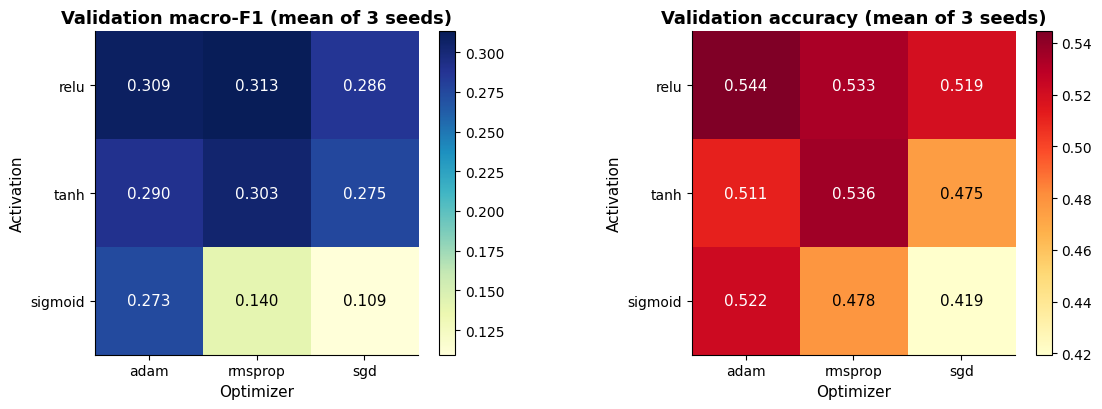

Best combination by mean validation macro-F1: activation = relu, optimizer = rmsprop (macro-F1 0.313 +/- 0.005)
Spread between best and worst combination: 0.204 vs typical seed-to-seed std 0.031 -> differences are larger than seed noise

Test-set comparison (reported once, not used for selection):
                                 test accuracy  test macro-F1  test within +/-1 star
Section 3.5 model (relu + adam)          0.535          0.282                  0.805
Grid winner (relu + rmsprop)             0.495          0.279                  0.835

              precision    recall  f1-score   support

      1 star      0.455     0.294     0.357        17
      2 star      0.143     0.100     0.118        10
      3 star      0.091     0.105     0.098        19
      4 star      0.143     0.105     0.121        38
      5 star      0.659     0.750     0.702       116

    accuracy                          0.495       200
   macro avg      0.298     0.271     0.279       200
weighted av

In [24]:
if BACKEND == "keras":
    pivot_f1 = grid_df.pivot_table(index="activation", columns="optimizer", values="val macro-F1", aggfunc="mean").loc[ACTIVATIONS, OPTIMIZERS]
    pivot_acc = grid_df.pivot_table(index="activation", columns="optimizer", values="val accuracy", aggfunc="mean").loc[ACTIVATIONS, OPTIMIZERS]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, pivot, ttl, cmap in [(axes[0], pivot_f1, "Validation macro-F1 (mean of 3 seeds)", "YlGnBu"),
                                 (axes[1], pivot_acc, "Validation accuracy (mean of 3 seeds)", "YlOrRd")]:
        im = ax.imshow(pivot.values, cmap=cmap, vmin=pivot.values.min(), vmax=pivot.values.max())
        ax.set_xticks(range(len(OPTIMIZERS))); ax.set_xticklabels(OPTIMIZERS)
        ax.set_yticks(range(len(ACTIVATIONS))); ax.set_yticklabels(ACTIVATIONS)
        ax.set_xlabel("Optimizer"); ax.set_ylabel("Activation"); ax.set_title(ttl); ax.grid(False)
        for i in range(len(ACTIVATIONS)):
            for k in range(len(OPTIMIZERS)):
                v = pivot.values[i, k]
                ax.text(k, i, f"{v:.3f}", ha="center", va="center", fontsize=11,
                        color="white" if v > (pivot.values.min() + pivot.values.max()) / 2 else "black")
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout(); plt.show()

    best_combo = grid_summary["macro_f1_mean"].idxmax()
    best_act, best_opt = best_combo
    print(f"Best combination by mean validation macro-F1: activation = {best_act}, optimizer = {best_opt} "
          f"(macro-F1 {grid_summary.loc[best_combo, 'macro_f1_mean']:.3f} +/- {grid_summary.loc[best_combo, 'macro_f1_std']:.3f})")
    spread = grid_summary["macro_f1_mean"].max() - grid_summary["macro_f1_mean"].min()
    typical_sd = grid_summary["macro_f1_std"].mean()
    print(f"Spread between best and worst combination: {spread:.3f} vs typical seed-to-seed std {typical_sd:.3f} "
          f"-> {'differences are larger than seed noise' if spread > 2 * typical_sd else 'differences are comparable to seed noise'}")

    #  one look at the test set: retrain the winner (seed 42) and compare with the section 3.5 model
    best_model_, _, best_ep_final = train_keras_variant(base_cfg, best_act, best_opt, SEED)
    proba_best = np.asarray(best_model_(Xtest_tfidf.toarray(), training=False))
    pred_best = proba_best.argmax(1)
    compare_variants = pd.DataFrame({
        "test accuracy": [acc, accuracy_score(y_test, pred_best)],
        "test macro-F1": [macro_f1, f1_score(y_test, pred_best, average="macro", zero_division=0)],
        "test within +/-1 star": [within_one, np.mean(np.abs(pred_best - y_test) <= 1)]},
        index=[f"Section 3.5 model (relu + adam)", f"Grid winner ({best_act} + {best_opt})"])
    print("\nTest-set comparison (reported once, not used for selection):")
    print(compare_variants.round(3).to_string())
    print()
    print(classification_report(y_test, pred_best, labels=range(5), target_names=CLASS_NAMES, zero_division=0, digits=3))

**Results and interpretation (3 seeds per cell; validation set of 120 reviews; architecture of configuration C).**

| Activation | Adam | RMSprop | SGD + momentum |
|---|---|---|---|
| ReLU | 0.309 ± 0.016 | **0.313 ± 0.005** | 0.286 ± 0.049 |
| tanh | 0.290 ± 0.005 | 0.303 ± 0.026 | 0.275 ± 0.058 |
| sigmoid | 0.273 ± 0.039 | 0.140 ± 0.013 | 0.109 ± 0.066 |

(mean ± standard deviation of validation macro-F1; for reference, always predicting 5 stars scores 0.147.)

- **Best combination:** ReLU with RMSprop (0.313), but ReLU + Adam (0.309), tanh + RMSprop (0.303) and tanh + Adam (0.290) are within about one to two seed-to-seed standard deviations of it. The top group is therefore **statistically indistinguishable** on this small validation set; ReLU with an adaptive optimizer (Adam or RMSprop) is the safe choice, which is what §3.3 used.
- **Where the large differences are.** The overall spread (0.204) is much bigger than seed noise (average std 0.031), but it comes from a few failures: **sigmoid with RMSprop (0.140) and with SGD (0.109)** score at or below the always-5-stars level, i.e. these networks essentially collapsed onto the majority class. Sigmoid + Adam did learn, but needed on average 21 epochs to reach its best validation loss versus 2–4 for the other adaptive-optimizer runs, consistent with the slower learning typically seen with saturating activations.
- **SGD** (learning rate 0.05, momentum 0.9) was the least stable: its validation accuracy varied a lot between seeds (standard deviation 0.10–0.28), so some runs ended in poor solutions. A different learning rate could change this; we did not tune it.
- **Test check.** The grid winner (ReLU + RMSprop, retrained with the base seed) reached test accuracy 0.495, macro-F1 0.279 and 83.5% within one star, compared with 0.535, 0.282 and 80.5% for the §3.5 model (ReLU + Adam). So the validation "winner" is **not better on the test set**: macro-F1 is equal for practical purposes, accuracy is lower, and per-class scores move around by amounts (e.g. 1-star F1 0.357 vs 0.286) that are well within what 17 test reviews can produce. We keep ReLU + Adam as the final model.
- **Takeaway.** Activation and optimizer matter mainly when a combination fails (sigmoid with RMSprop or SGD); among sensible choices the differences are smaller than the noise in a ~800-review dataset.

## 3.8 The same MLP in PyTorch

**Purpose.** The MLP in a second framework and comparing workflows. This section rebuilds the network from §3.3 in **PyTorch**, using exactly the same data splits, TF-IDF features, oversampling setting, hidden layers, dropout, learning rate (0.001, Adam), batch size (32) and early-stopping rule (validation loss, patience 5, best weights restored).

**Differences in workflow worth noticing.**

Keras automates training with `fit` and callbacks, while PyTorch requires a manual training loop. PyTorch uses logits with `CrossEntropyLoss`, applying softmax only for evaluation. Different initialization and data shuffling can lead to different results, and this section requires PyTorch.

In [25]:
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import TensorDataset, DataLoader
    TORCH_OK = True
except Exception as exc:
    TORCH_OK = False
    print(f"PyTorch is not available ({type(exc).__name__}). Install it yourself with `pip install torch` to run section 3.8.")

if TORCH_OK:
    torch.manual_seed(SEED)
    base_cfg_t = next(c for c in CONFIGS if c["name"] == final_name)      # same architecture as section 3.3 / 3.7
    print(f"PyTorch {torch.__version__} | architecture: hidden = {base_cfg_t['hidden']}, dropout = {base_cfg_t['dropout']}, "
          f"oversampling = {base_cfg_t['oversample']}")

    Xt_np, yt_np = oversample(Xtr_tfidf, y_tr) if base_cfg_t["oversample"] else (Xtr_tfidf, y_tr)
    to_tensor = lambda M: torch.tensor(M.toarray(), dtype=torch.float32)
    Xt_t, Xv_t, Xte_t = to_tensor(Xt_np), to_tensor(Xval_tfidf), to_tensor(Xtest_tfidf)
    yt_t = torch.tensor(np.asarray(yt_np), dtype=torch.long)
    yv_t = torch.tensor(np.asarray(y_val), dtype=torch.long)

    layers_t, in_dim = [], Xt_t.shape[1]
    for units in base_cfg_t["hidden"]:
        layers_t += [nn.Linear(in_dim, units), nn.ReLU(), nn.Dropout(base_cfg_t["dropout"])]
        in_dim = units
    layers_t.append(nn.Linear(in_dim, N_CLASSES))                        # raw logits (softmax is inside the loss)
    torch_net = nn.Sequential(*layers_t)
    print(torch_net)

    loss_fn = nn.CrossEntropyLoss()
    optimizer_t = torch.optim.Adam(torch_net.parameters(), lr=1e-3)
    loader = DataLoader(TensorDataset(Xt_t, yt_t), batch_size=BATCH, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))

    def torch_eval(X_, y_):
        torch_net.eval()
        with torch.no_grad():
            logits = torch_net(X_)
            loss_value = loss_fn(logits, y_).item()
            proba_ = torch.softmax(logits, dim=1).numpy()
        return loss_value, proba_

    pt_hist = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
    best_val, best_state, best_epoch_t, wait = np.inf, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        torch_net.train()
        for xb, yb in loader:
            optimizer_t.zero_grad()
            loss_batch = loss_fn(torch_net(xb), yb)
            loss_batch.backward()
            optimizer_t.step()
        tr_loss, tr_proba = torch_eval(Xt_t, yt_t)
        va_loss, va_proba = torch_eval(Xv_t, yv_t)
        pt_hist["loss"].append(tr_loss); pt_hist["val_loss"].append(va_loss)
        pt_hist["accuracy"].append(accuracy_score(np.asarray(yt_np), tr_proba.argmax(1)))
        pt_hist["val_accuracy"].append(accuracy_score(y_val, va_proba.argmax(1)))
        if va_loss < best_val - 1e-4:
            best_val, best_epoch_t, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(torch_net.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    torch_net.load_state_dict(best_state)                                # restore the best epoch
    print(f"Stopped after {len(pt_hist['loss'])} epochs; best epoch = {best_epoch_t}")

PyTorch 2.11.0+cpu | architecture: hidden = (128, 64), dropout = 0.5, oversampling = True
Sequential(
  (0): Linear(in_features=3000, out_features=128, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.5, inplace=False)
  (6): Linear(in_features=64, out_features=5, bias=True)
)
Stopped after 8 epochs; best epoch = 3


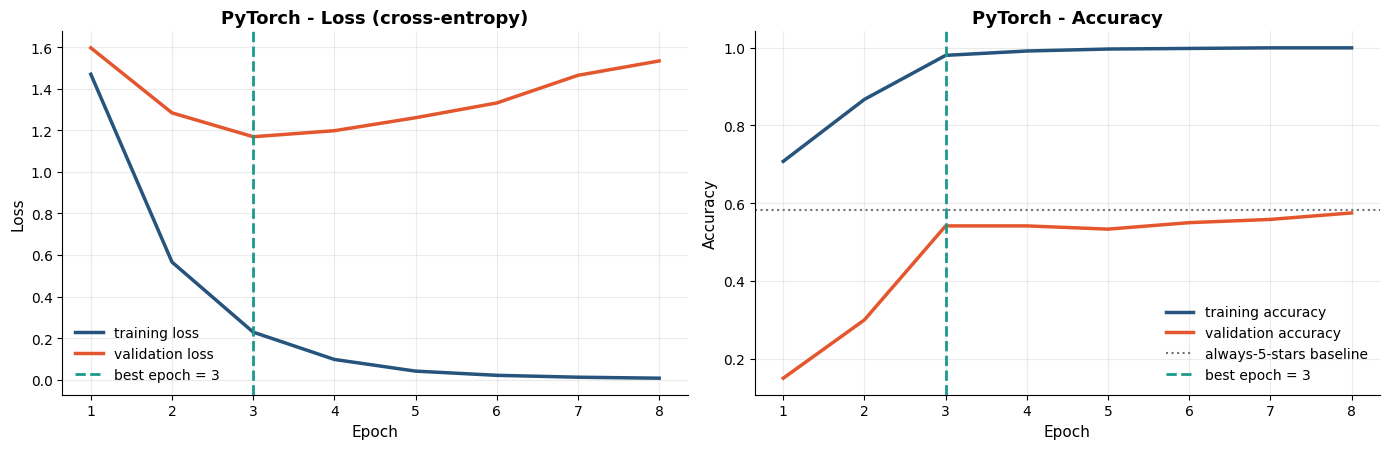

PyTorch test accuracy: 0.530 | macro-F1: 0.292 | within +/-1 star: 78.5%

              precision    recall  f1-score   support

      1 star      0.368     0.412     0.389        17
      2 star      0.000     0.000     0.000        10
      3 star      0.095     0.105     0.100        19
      4 star      0.296     0.211     0.246        38
      5 star      0.685     0.767     0.724       116

    accuracy                          0.530       200
   macro avg      0.289     0.299     0.292       200
weighted avg      0.494     0.530     0.509       200



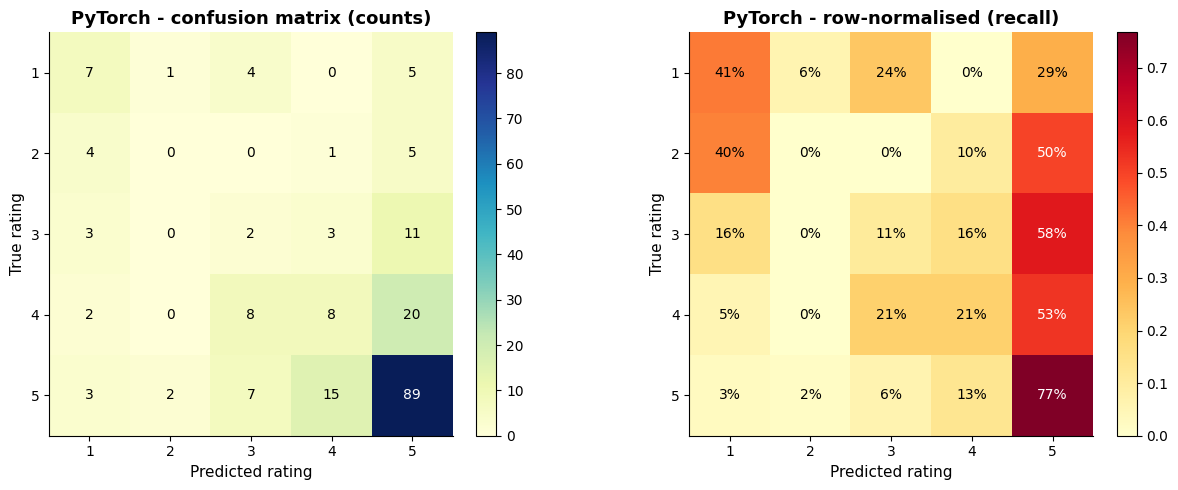

Same architecture, same data, two frameworks:
                       best epoch  test accuracy  test macro-F1
keras (section 3.5)             3          0.535          0.282
PyTorch (section 3.8)           3          0.530          0.292
Prediction agreement between the two models on the test set: 78.5%


In [26]:
if TORCH_OK:
    # learning curves
    ep_t = np.arange(1, len(pt_hist["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
    axes[0].plot(ep_t, pt_hist["loss"], color=PALETTE["navy"], lw=2.5, label="training loss")
    axes[0].plot(ep_t, pt_hist["val_loss"], color=PALETTE["coral"], lw=2.5, label="validation loss")
    axes[1].plot(ep_t, pt_hist["accuracy"], color=PALETTE["navy"], lw=2.5, label="training accuracy")
    axes[1].plot(ep_t, pt_hist["val_accuracy"], color=PALETTE["coral"], lw=2.5, label="validation accuracy")
    axes[1].axhline(majority_share, color=PALETTE["grey"], ls=":", lw=1.5, label="always-5-stars baseline")
    for ax, ttl, yl in [(axes[0], "Loss (cross-entropy)", "Loss"), (axes[1], "Accuracy", "Accuracy")]:
        ax.axvline(best_epoch_t, color=PALETTE["teal"], ls="--", lw=2, label=f"best epoch = {best_epoch_t}")
        ax.set_title(f"PyTorch - {ttl}"); ax.set_xlabel("Epoch"); ax.set_ylabel(yl); ax.legend()
    plt.tight_layout(); plt.show()

    # test-set evaluation
    _, proba_t = torch_eval(Xte_t, torch.tensor(np.asarray(y_test), dtype=torch.long))
    pred_t = proba_t.argmax(1)
    acc_t = accuracy_score(y_test, pred_t)
    f1_t = f1_score(y_test, pred_t, average="macro", zero_division=0)
    print(f"PyTorch test accuracy: {acc_t:.3f} | macro-F1: {f1_t:.3f} | within +/-1 star: {np.mean(np.abs(pred_t - y_test) <= 1):.1%}\n")
    print(classification_report(y_test, pred_t, labels=range(5), target_names=CLASS_NAMES, zero_division=0, digits=3))

    cm_t = confusion_matrix(y_test, pred_t, labels=range(5))
    cm_t_norm = cm_t / cm_t.sum(axis=1, keepdims=True).clip(min=1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    plot_cm(axes[0], cm_t, "PyTorch - confusion matrix (counts)", "YlGnBu", "d")
    plot_cm(axes[1], cm_t_norm, "PyTorch - row-normalised (recall)", "YlOrRd", ".0%")
    plt.tight_layout(); plt.show()

    # Keras vs PyTorch on the same split
    framework_cmp = pd.DataFrame({
        "best epoch": [final_run["best_epoch"] if BACKEND == "keras" else np.nan, best_epoch_t],
        "test accuracy": [acc, acc_t], "test macro-F1": [macro_f1, f1_t]},
        index=[f"{BACKEND} (section 3.5)", "PyTorch (section 3.8)"])
    print("Same architecture, same data, two frameworks:")
    print(framework_cmp.round(3).to_string())
    print(f"Prediction agreement between the two models on the test set: {np.mean(pred_t == y_pred):.1%}")

**Results and interpretation (PyTorch vs Keras, same data and architecture).**

| | Best epoch | Test accuracy | Test macro-F1 | Within ±1 star |
|---|---|---|---|---|
| Keras (§3.5) | 3 | 0.535 | 0.282 | 80.5% |
| PyTorch (§3.8) | 3 | 0.530 | 0.292 | 78.5% |

Keras and PyTorch performed similarly overall, but agreed on only 78.5% of individual predictions. Both did best on 5-star reviews and struggled with minority ratings. With so few test examples per class, the differences are too uncertain to say one framework is better.

**Limits of these results.**

- **Class imbalance** limits the minority classes: 2-star reviews are under 5% of the data and only 10 land in the test set. Oversampling (config C) was the tested remedy; it improved macro-F1 on validation but did not make the minority classes reliable.
- **Generalisability.** The test set has 200 reviews and a single split was used, so any metric could move by several points with a different split; no confidence intervals or repeated splits are reported. The model reflects the vocabulary of these 40 products and may not transfer to other product types.
- **Ideas for improvement:** more data, k-fold cross-validation (it would also give confidence intervals on the metrics), a class-weighted logistic regression as a fairer baseline, ordinal-aware losses, pre-trained text embeddings, or reframing the task as 3-class sentiment or ordinal regression if exact stars are not needed.

---

